# COMP4318/5318 Assignment 2: Image Classification

### Group number: 123  , SID1: 550394172 , SID2: 550378183 SID3: 550894694

We compare Random Forest, MLP and CNN classifiers on the
provided PathMNIST dataset. The notebook includes data
exploration and preprocessing, model definitions,
hyperparameter searches, and final test-set evaluation.
All three models use the same training/validation split.

## Setup and dependencies

This notebook uses NumPy, pandas, SciPy, scikit-learn,
Matplotlib, joblib and IPython, along with Keras using
the TensorFlow backend.

Place the Assignment2Data folder in the working directory.
It should contain X_train.npy, y_train.npy, X_test.npy
and y_test.npy.

In [2]:
from IPython.display import display, Image
"""Auditable staged Random Forest optimisation; test data are used only after selection."""
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import json
import os
import platform
import shutil
import traceback
import numpy as np
import pandas as pd
import sklearn
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROOT = Path.cwd()

# Original assignment arrays:
# X_train.npy, y_train.npy, X_test.npy, y_test.npy
DATA = ROOT / "Assignment2Data"

# Separate folder for results generated by the merged notebook.
RUN = ROOT / "merged_rf_results_fresh_01"

SEED = 42
JOBS = 4

def utc(): return datetime.now(timezone.utc).isoformat()
def dump(path, obj):
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')
def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()
def event(kind, **details):
    item={'timestamp_utc':utc(), 'event':kind, **details}
    with (RUN/'events.jsonl').open('a',encoding='utf-8') as f: f.write(json.dumps(item,ensure_ascii=False)+'\n')
    print(json.dumps(item,ensure_ascii=False),flush=True)

def features(images, name):
    x=images.astype(np.float32)/255.
    if name=='raw_rgb': return x.reshape(len(x),-1)
    if name=='pooled_rgb': return x.reshape(-1,14,2,14,2,3).mean(axis=(2,4)).reshape(len(x),-1)
    if name=='colour_texture':
        # Fixed, non-learned descriptors: 7x7 spatial blocks of size 4x4.
        blocks=x.reshape(-1,7,4,7,4,3)
        mean=blocks.mean(axis=(2,4)).reshape(len(x),-1)
        std=blocks.std(axis=(2,4)).reshape(len(x),-1)
        # Per-channel 16-bin histograms, normalised to sum to one.
        bins=np.minimum((x*16).astype(np.int16),15).reshape(len(x),-1,3)
        hist=np.stack([(bins[:,:,c]==b).mean(axis=1) for c in range(3) for b in range(16)],axis=1)
        quant=np.quantile(x.reshape(len(x),-1,3),[.1,.25,.5,.75,.9],axis=1).transpose(1,0,2).reshape(len(x),-1)
        return np.concatenate([mean,std,hist,quant],axis=1).astype(np.float32)
    raise ValueError(name)

def initialise():
    RUN.mkdir(parents=True, exist_ok=True)
    if not (RUN/'manifest.json').exists():
        dump(RUN/'manifest.json',{'created_utc':utc(),'python':platform.python_version(),
             'sklearn':sklearn.__version__,'numpy':np.__version__,'platform':platform.platform(),
             'seed':SEED,'n_jobs':JOBS,'selection_metric':'validation macro-F1',
             'data_sha256':{p.name:digest(p) for p in DATA.glob('*.npy')},
             'prior_test_exposure':'Original 8-trial experiment has already evaluated this test set. Further choices use validation only; this is not a never-seen test set.',
             'scope':'Best among the evaluated configurations, not a global optimum.'})
        dump(RUN/'plan.json',{
          'stage1':'3 feature representations x leaf sizes [1,4], 100 trees, sqrt features, unlimited depth',
          'stage2':'Best representation; 100 trees; max_features [sqrt,0.1,0.3] x max_depth [16,None] x leaf [1,4]',
          'stage3':'Best two structural configurations; compare 200 and 400 trees',
          'stage4':'Best two stage3 candidates; repeat at seeds 17 and 73, rank mean validation macro-F1 over seeds 42,17,73',
          'final':'Freeze configuration; refit all training data with seed 42; evaluate provided test set once for this run',
          'tie_break':'macro-F1 then accuracy; stable earlier trial order',
          'limitation':'One fixed validation split is reused; seed repeats measure model randomness, not split uncertainty.'})
        event('initialised')
    images=np.load(DATA/'X_train.npy',allow_pickle=False)
    y=np.load(DATA/'y_train.npy',allow_pickle=False).ravel()
    splitfile=RUN/'split_indices.npz'
    if not splitfile.exists():
        fit,val=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
        np.savez(splitfile,fit_idx=fit,val_idx=val)
    with np.load(splitfile) as z: fit,val=z['fit_idx'],z['val_idx']
    np.save(RUN/'training_labels.npy',y)
    return images,y,fit,val

def records():
    return [json.loads(p.read_text(encoding='utf-8')) for p in sorted((RUN/'trials').glob('*/result.json'))]

def trial(stage, representation, params, seed, images, y, fit, val, cache):
    config={'representation':representation,'params':params,'seed':seed}
    key=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:12]
    folder=RUN/'trials'/key; folder.mkdir(parents=True,exist_ok=True)
    if (folder/'result.json').exists():
        event('reuse_trial',stage=stage,trial_id=key)
        return json.loads((folder/'result.json').read_text(encoding='utf-8'))
    model=RandomForestClassifier(**params,random_state=seed,n_jobs=JOBS)
    dump(folder/'config.json',{'stage':stage,**config,'full_estimator_params':model.get_params(),'started_utc':utc()})
    event('trial_started',stage=stage,trial_id=key,**config)
    try:
        if representation not in cache:
            start=perf_counter(); cache[representation]=features(images,representation)
            event('features_ready',representation=representation,seconds=perf_counter()-start,dimensions=cache[representation].shape[1])
        X=cache[representation]; start=perf_counter()
        model.fit(X[fit],y[fit]); fit_seconds=perf_counter()-start
        start=perf_counter(); proba=model.predict_proba(X[val]); predict_seconds=perf_counter()-start
        pred=model.classes_[proba.argmax(axis=1)]; trainpred=model.predict(X[fit])
        result={'trial_id':key,'stage':stage,**config,'finished_utc':utc(),
            'feature_count':X.shape[1],'fit_samples':len(fit),'val_samples':len(val),
            'train_accuracy':accuracy_score(y[fit],trainpred),'train_macro_f1':f1_score(y[fit],trainpred,average='macro'),
            'val_accuracy':accuracy_score(y[val],pred),'val_macro_f1':f1_score(y[val],pred,average='macro'),
            'fit_seconds':fit_seconds,'val_predict_seconds':predict_seconds}
        np.savez_compressed(folder/'predictions.npz',fit_indices=fit,train_true=y[fit],train_pred=trainpred,
            val_indices=val,val_true=y[val],val_pred=pred,val_probabilities=proba,classes=model.classes_)
        pd.DataFrame(classification_report(y[val],pred,output_dict=True,zero_division=0)).T.to_csv(folder/'classification_report.csv')
        np.save(folder/'confusion_matrix.npy',confusion_matrix(y[val],pred,labels=model.classes_))
        joblib.dump(model,folder/'model.joblib',compress=3)
        dump(folder/'result.json',result)
        flat=[{**{k:v for k,v in r.items() if k!='params'},**r['params']} for r in records()]
        pd.DataFrame(flat).to_csv(RUN/'all_trials.csv',index=False)
        event('trial_finished',**result)
        return result
    except Exception:
        (folder/'error.txt').write_text(traceback.format_exc(),encoding='utf-8')
        event('trial_failed',trial_id=key)
        raise

def ranked(rows): return sorted(rows,key=lambda r:(r['val_macro_f1'],r['val_accuracy']),reverse=True)

def optimise():
    if (RUN/'selection_frozen.json').exists():
        event('reuse_frozen_selection')
        return json.loads((RUN/'selection_frozen.json').read_text(encoding='utf-8'))
    images,y,fit,val=initialise(); cache={}
    def run(stage,rep,p,seed=SEED): return trial(stage,rep,p,seed,images,y,fit,val,cache)
    stage1=[]
    for rep in ['pooled_rgb','raw_rgb','colour_texture']:
        for leaf in [1,4]:
            stage1.append(run('1_features',rep,dict(n_estimators=100,max_features='sqrt',max_depth=None,min_samples_leaf=leaf)))
    rep=ranked(stage1)[0]['representation']
    event('feature_selected',representation=rep,criterion='validation macro-F1')
    stage2=[]
    for p in ParameterGrid({'max_features':['sqrt',.1,.3],'max_depth':[16,None],'min_samples_leaf':[1,4]}):
        stage2.append(run('2_structure',rep,dict(n_estimators=100,**p)))
    stage3=[]
    for r in ranked(stage2)[:2]:
        for n in [200,400]: stage3.append(run('3_tree_count',rep,{**r['params'],'n_estimators':n}))
    candidates=[]
    for r in ranked(stage3)[:2]:
        repeats=[r]+[run('4_seed_stability',rep,r['params'],seed) for seed in [17,73]]
        candidates.append({'representation':rep,'params':r['params'],'trial_ids':[v['trial_id'] for v in repeats],
            'mean_val_macro_f1':float(np.mean([v['val_macro_f1'] for v in repeats])),
            'std_val_macro_f1':float(np.std([v['val_macro_f1'] for v in repeats],ddof=1)),
            'mean_val_accuracy':float(np.mean([v['val_accuracy'] for v in repeats]))})
    best=max(candidates,key=lambda r:(r['mean_val_macro_f1'],r['mean_val_accuracy']))
    dump(RUN/'seed_comparison.json',candidates)
    dump(RUN/'selection_frozen.json',{'frozen_utc':utc(),**best,'final_seed':SEED})
    event('selection_frozen',**best)
    return best

def final_evaluation(config):
    # Independent of search variables: only the literal config and original arrays are needed.
    dest=RUN/'final';dest.mkdir(parents=True,exist_ok=True)
    if (dest/'metrics.json').exists():
        saved=json.loads((dest/'config.json').read_text(encoding='utf-8'))
        if saved['representation'] != config['representation'] or any(saved['full_estimator_params'][k]!=v for k,v in config['params'].items()):
            raise ValueError('Cached final model has different parameters. Choose a new RUN directory; do not overwrite the audit trail.')
        event('final_already_completed')
        return json.loads((dest/'metrics.json').read_text(encoding='utf-8'))
    images=np.load(DATA/'X_train.npy',allow_pickle=False); y=np.load(DATA/'y_train.npy',allow_pickle=False).ravel()
    start=perf_counter(); X=features(images,config['representation']); train_feature_s=perf_counter()-start
    model=RandomForestClassifier(**config['params'],random_state=SEED,n_jobs=JOBS)
    dump(dest/'config.json',{'representation':config['representation'],'full_estimator_params':model.get_params()})
    start=perf_counter();model.fit(X,y);fit_s=perf_counter()-start
    joblib.dump(model,dest/'model.joblib',compress=3)
    # Test arrays are first loaded here, after configuration freezing and final fitting.
    xt=np.load(DATA/'X_test.npy',allow_pickle=False);yt=np.load(DATA/'y_test.npy',allow_pickle=False).ravel()
    start=perf_counter();Xt=features(xt,config['representation']);test_feature_s=perf_counter()-start
    start=perf_counter();prob=model.predict_proba(Xt);pred=model.classes_[prob.argmax(axis=1)];predict_s=perf_counter()-start
    np.savez_compressed(dest/'test_predictions.npz',sample_indices=np.arange(len(yt)),true_labels=yt,predicted_labels=pred,probabilities=prob,classes=model.classes_)
    table=pd.DataFrame({'sample_index':np.arange(len(yt)),'true_label':yt,'predicted_label':pred})
    for i,c in enumerate(model.classes_):table[f'prob_class_{c}']=prob[:,i]
    table.to_csv(dest/'test_predictions.csv',index=False)
    pd.DataFrame(classification_report(yt,pred,output_dict=True,zero_division=0)).T.to_csv(dest/'classification_report.csv')
    cm=confusion_matrix(yt,pred,labels=model.classes_);np.save(dest/'confusion_matrix.npy',cm)
    metrics={'test_accuracy':accuracy_score(yt,pred),'test_macro_f1':f1_score(yt,pred,average='macro'),
       'train_samples':len(y),'test_samples':len(yt),'fit_seconds':fit_s,'predict_seconds':predict_s,
       'train_feature_seconds':train_feature_s,'test_feature_seconds':test_feature_s}
    dump(dest/'metrics.json',metrics);event('final_completed',**metrics)
    return metrics


In [3]:
# File paths and runtime measurement
from pathlib import Path
from time import perf_counter

# Data handling and visualisation
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Neural network
import keras
from keras import layers

# Preprocessing, hyperparameter search, and evaluation
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Random seed for reproducibility
SEED_MLP = 42
keras.utils.set_random_seed(SEED_MLP)

In [3]:
# Additional metrics used by the CNN.
from sklearn.metrics import precision_score, recall_score

SEED_CNN = 42

RESULTS_DIR_CNN = ROOT / "results_cnn"
RESULTS_DIR_CNN.mkdir(parents=True, exist_ok=True)

CLASS_NAMES_CNN = [
    "adipose",
    "background",
    "debris",
    "lymphocytes",
    "mucus",
    "smooth muscle",
    "normal colon mucosa",
    "cancer-assoc. stroma",
    "colorectal adenocarcinoma epith.",
]

NUM_CLASSES_CNN = len(CLASS_NAMES_CNN)

print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())

Keras: 3.15.1
Backend: tensorflow


## 1. Data loading, exploration, and preprocessing


### Shared data split and fixed features

The training set contains 32,000 RGB images of size 28×28
from nine classes. Class counts range from 2,728 to 4,697.
We use a stratified 80/20 split with random seed 42, giving
25,600 training and 6,400 validation samples. All three
models use the same split.

The selected RF and the MLP use 357 colour and local
statistical features. Each image is divided into a 7×7 grid
of 4×4-pixel blocks. The features consist of:

- 147 block means: 49 blocks × 3 colour channels.
- 147 block standard deviations.
- 48 colour-histogram values: 16 bins per channel.
- 15 quantiles: five per channel.

These features summarise colour and local variation, but
discard some fine spatial detail. They are calculated
separately for each image without learning statistics across
samples. The MLP features are then standardised using a scaler
fitted only on the training subset during tuning.

In [4]:
# Load the original training images and create/reuse
# Member A's stratified training/validation split.
images, y, fit_idx, val_idx = initialise()

assert images.shape[1:] == (28, 28, 3)
assert len(images) == len(y)
assert np.intersect1d(fit_idx, val_idx).size == 0
assert np.array_equal(
    np.sort(np.concatenate([fit_idx, val_idx])),
    np.arange(len(y)),
)

print("Original training images:", images.shape)
print("Training subset size:", len(fit_idx))
print("Validation subset size:", len(val_idx))

print("\nTraining class counts:")
print(pd.Series(y).value_counts().sort_index())

# Generate the same fixed 357-dimensional representation
# used by the selected RF and the MLP.
feature_start_mlp = perf_counter()

X_train_all_mlp = features(images, "colour_texture")
y_train_all_mlp = y.astype("int64").ravel()

train_feature_seconds_mlp = perf_counter() - feature_start_mlp

assert X_train_all_mlp.shape == (len(y_train_all_mlp), 357)

# Both models use exactly the same split indices.
fit_idx_mlp = fit_idx
val_idx_mlp = val_idx

X_fit_mlp = X_train_all_mlp[fit_idx_mlp]
y_fit_mlp = y_train_all_mlp[fit_idx_mlp]

X_val_mlp = X_train_all_mlp[val_idx_mlp]
y_val_mlp = y_train_all_mlp[val_idx_mlp]

print("\nMLP training features:", X_fit_mlp.shape)
print("MLP validation features:", X_val_mlp.shape)
print("Number of classes:", len(np.unique(y_train_all_mlp)))
print(
    f"Training feature extraction time: "
    f"{train_feature_seconds_mlp:.2f}s"
)

Original training images: (32000, 28, 28, 3)
Training subset size: 25600
Validation subset size: 6400

Training class counts:
0    3490
1    3431
2    3505
3    3656
4    2950
5    4290
6    2728
7    3253
8    4697
Name: count, dtype: int64

MLP training features: (25600, 357)
MLP validation features: (6400, 357)
Number of classes: 9
Training feature extraction time: 2.65s


### Original images and local feature maps

We display one example from each class in the fitting subset.
The rows show the original RGB image, local RGB means, and
local RGB standard deviations. Each summary map contains
7×7 blocks, calculated from non-overlapping 4×4 pixel regions.

These maps visualise the first 294 components of the fixed
357-dimensional descriptor. Histograms and quantiles are not
shown. The standard-deviation maps use a common display scale
across the nine examples.

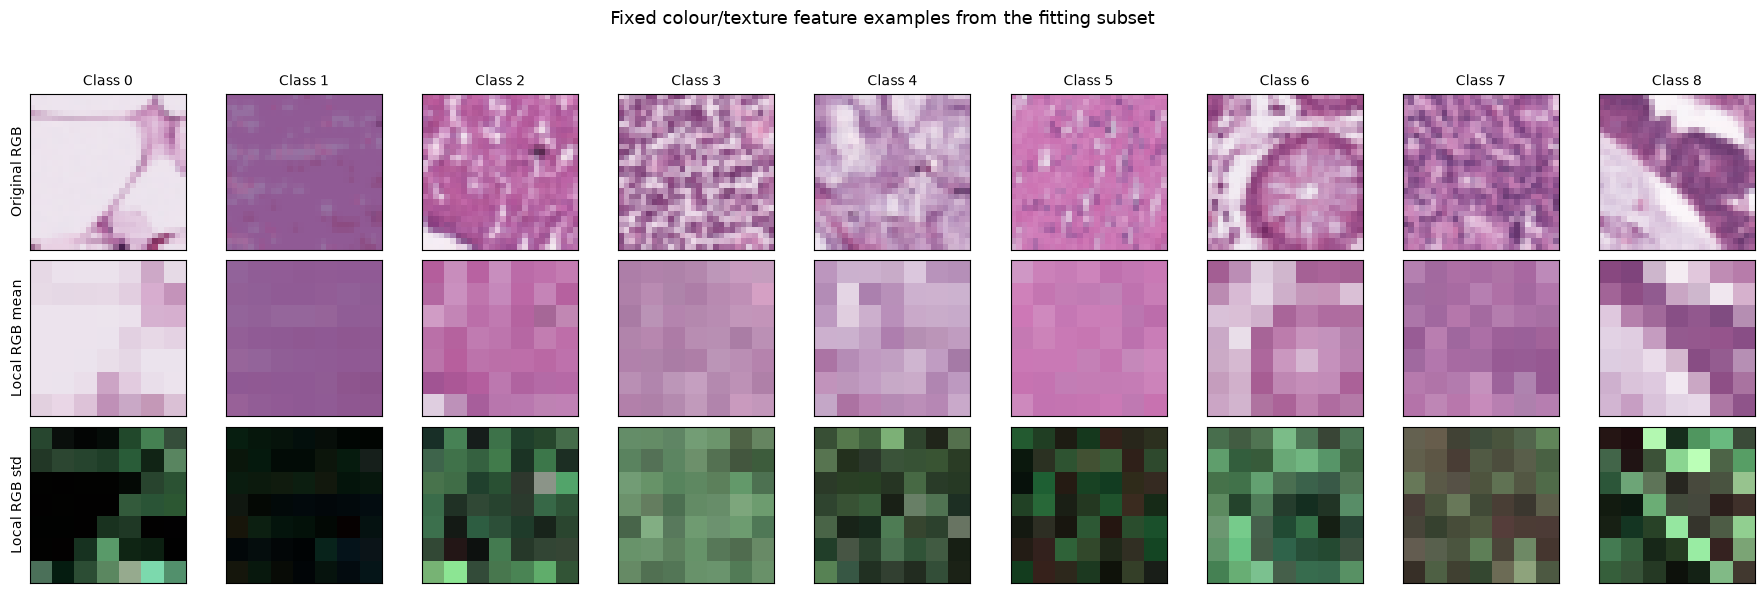

Sample indices in X_train.npy: [7694, 26635, 485, 3514, 27129, 18141, 30846, 25906, 23622]
RGB standard-deviation maps share a display scale of 0 to 0.2832.


In [5]:
# Visualise the local statistics used by features(..., "colour_texture").
# Select the first fitting-subset example from each class.
example_indices_rf = np.array([
    fit_idx[np.flatnonzero(y[fit_idx] == class_id)[0]]
    for class_id in range(9)
])

example_images_rf = images[example_indices_rf]
example_features_rf = features(
    example_images_rf, "colour_texture"
)

# features() stores 147 local means, then 147 local standard deviations.
mean_maps_rf = example_features_rf[:, :147].reshape(9, 7, 7, 3)
std_maps_rf = example_features_rf[:, 147:294].reshape(9, 7, 7, 3)

# Apply one common scale for displaying RGB standard deviations.
# This affects only the plot, not the model features.
std_display_max_rf = float(std_maps_rf.max())
std_display_rf = std_maps_rf / max(std_display_max_rf, 1e-8)

fig, axes = plt.subplots(3, 9, figsize=(18, 6))

for class_id in range(9):
    axes[0, class_id].imshow(example_images_rf[class_id])
    axes[1, class_id].imshow(
        mean_maps_rf[class_id], interpolation="nearest"
    )
    axes[2, class_id].imshow(
        std_display_rf[class_id], interpolation="nearest"
    )

    axes[0, class_id].set_title(f"Class {class_id}", fontsize=10)

    for row in range(3):
        axes[row, class_id].set_xticks([])
        axes[row, class_id].set_yticks([])

for row, label in enumerate([
    "Original RGB",
    "Local RGB mean",
    "Local RGB std",
]):
    axes[row, 0].set_ylabel(label, fontsize=10)

fig.suptitle(
    "Fixed colour/texture feature examples from the fitting subset",
    fontsize=13,
)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

print("Sample indices in X_train.npy:", example_indices_rf.tolist())
print(
    "RGB standard-deviation maps share a display scale of "
    f"0 to {std_display_max_rf:.4f}."
)

In [6]:
# Fit the scaler on the training subset only.
scaler_mlp = StandardScaler()

X_fit_scaled_mlp = scaler_mlp.fit_transform(
    X_fit_mlp
).astype("float32")

# Transform validation data using the same scaler.
X_val_scaled_mlp = scaler_mlp.transform(
    X_val_mlp
).astype("float32")

### Examples of preprocessed data

The table below shows the first eight standardised features
for five training samples, together with their class labels.
Negative values indicate feature values below the training
subset mean; positive values indicate values above it.

In [6]:
# Display selected features from five preprocessed samples.
preview_mlp = pd.DataFrame(
    X_fit_scaled_mlp[:5, :8],
    columns=[f"feature_{i}" for i in range(8)],
)
preview_mlp["label"] = y_fit_mlp[:5]

preview_mlp.round(4)

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,label
0,-0.2954,-1.0280,-0.8378,0.4223,0.1470,0.2815,-0.1469,-0.9269,2
1,-0.5307,-0.2260,-0.4236,-0.4095,-0.1423,-0.3145,-0.5028,-0.1509,3
2,0.6795,0.3946,0.6006,0.5434,-0.1626,0.2020,0.3680,-0.2999,5
3,1.4819,1.9910,1.7417,1.6668,2.2299,1.9767,1.6821,2.2516,0
4,-1.8866,-1.5819,-1.8268,-2.1922,-1.6855,-1.9634,0.6008,1.1637,8


### CNN preprocessing

The CNN uses the original 28×28×3 RGB images and shares the
same training/validation indices as RF and MLP.

Pixels are converted to float32 and divided by 255.
Each colour channel is then standardised using its mean
and standard deviation computed on the training subset only.
The same statistics are applied to validation images.

For final training, channel statistics are recomputed on all
32,000 training images and subsequently applied to test images.
The spatial image layout is preserved throughout.

In [7]:
# Reuse the original training images and labels loaded above.
X_train_all_cnn = images
y_train_all_cnn = y.astype("int64").ravel()

# Use the shared indices directly.
fit_idx_cnn = fit_idx
val_idx_cnn = val_idx

INPUT_SHAPE_CNN = X_train_all_cnn.shape[1:]

assert INPUT_SHAPE_CNN == (28, 28, 3)
assert np.array_equal(y_train_all_cnn, y_train_all_mlp)
assert np.array_equal(fit_idx_cnn, fit_idx_mlp)
assert np.array_equal(val_idx_cnn, val_idx_mlp)

print("CNN training images:", X_train_all_cnn.shape)
print("Shared training subset:", len(fit_idx_cnn))
print("Shared validation subset:", len(val_idx_cnn))


def fit_channel_stats_cnn(images):
    """Compute per-channel statistics from pixels scaled to [0, 1]."""
    scaled = images.astype("float64") / 255.0
    return (
        scaled.mean(axis=(0, 1, 2)).astype("float32"),
        scaled.std(axis=(0, 1, 2)).astype("float32"),
    )


def preprocess_cnn(images, channel_mean, channel_std):
    """Scale pixels and standardise each colour channel."""
    scaled = images.astype("float32") / 255.0
    return ((scaled - channel_mean) / channel_std).astype("float32")


# Fit preprocessing on the training subset only.
channel_mean_cnn, channel_std_cnn = fit_channel_stats_cnn(
    X_train_all_cnn[fit_idx_cnn]
)

assert np.all(channel_std_cnn > 0)

X_fit_cnn = preprocess_cnn(
    X_train_all_cnn[fit_idx_cnn],
    channel_mean_cnn,
    channel_std_cnn,
)
y_fit_cnn = y_train_all_cnn[fit_idx_cnn]

X_val_cnn = preprocess_cnn(
    X_train_all_cnn[val_idx_cnn],
    channel_mean_cnn,
    channel_std_cnn,
)
y_val_cnn = y_train_all_cnn[val_idx_cnn]

print("Channel mean:", np.round(channel_mean_cnn, 3))
print("Channel std:", np.round(channel_std_cnn, 3))
print("CNN training subset:", X_fit_cnn.shape)
print("CNN validation subset:", X_val_cnn.shape)

CNN training images: (32000, 28, 28, 3)
Shared training subset: 25600
Shared validation subset: 6400
Channel mean: [0.74  0.533 0.706]
Channel std: [0.125 0.179 0.126]
CNN training subset: (25600, 28, 28, 3)
CNN validation subset: (6400, 28, 28, 3)


Mean after preprocessing (R, G, B): [-0.  0. -0.]
Std after preprocessing  (R, G, B): [1. 1. 1.]
Value range: [-5.91, 2.55]


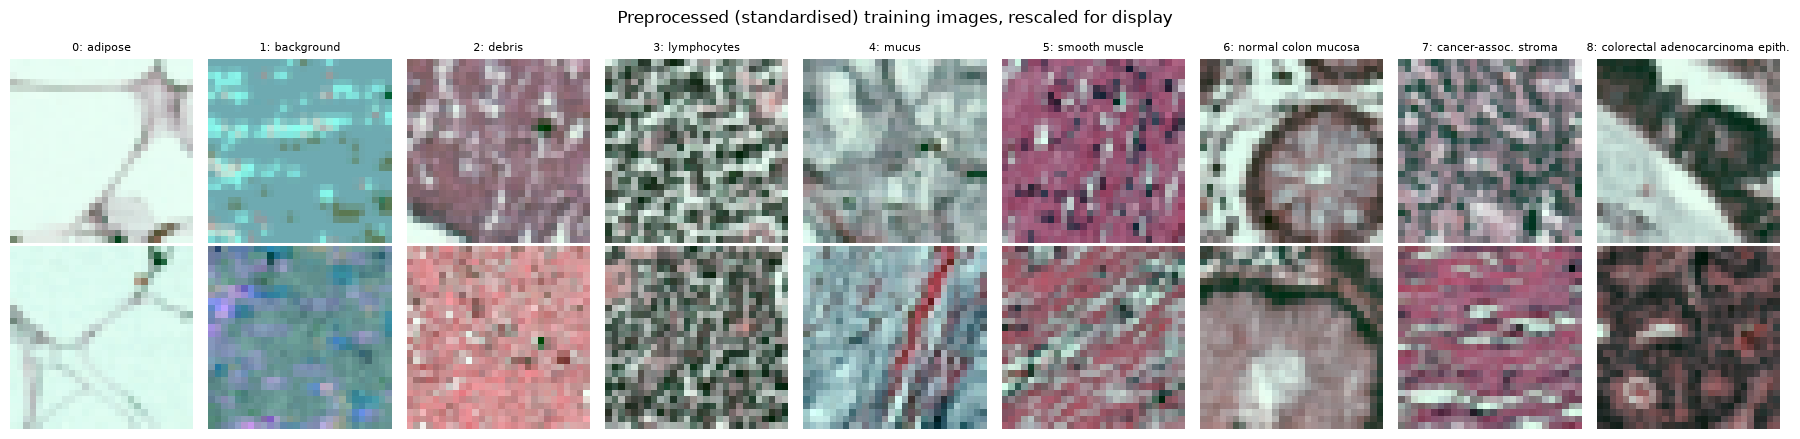

In [8]:
# Per-channel statistics of the preprocessed training subset (should be about 0 and 1)
print("Mean after preprocessing (R, G, B):",
      np.round(X_fit_cnn.mean(axis=(0, 1, 2), dtype="float64"), 3))
print("Std after preprocessing  (R, G, B):",
      np.round(X_fit_cnn.std(axis=(0, 1, 2), dtype="float64"), 3))
print(f"Value range: [{X_fit_cnn.min():.2f}, {X_fit_cnn.max():.2f}]")

# Two preprocessed training images from each class. Standardised values are not in [0, 1],
# so each image is min-max rescaled for display only.
fig, axes = plt.subplots(2, NUM_CLASSES_CNN, figsize=(18, 4.5))
for class_id, class_name in enumerate(CLASS_NAMES_CNN):
    class_rows = np.flatnonzero(y_fit_cnn == class_id)[:2]
    for row, sample in enumerate(class_rows):
        image = X_fit_cnn[sample]
        axes[row, class_id].imshow((image - image.min()) / (image.max() - image.min()))
        axes[row, class_id].axis("off")
    axes[0, class_id].set_title(f"{class_id}: {class_name}", fontsize=8)

fig.suptitle("Preprocessed (standardised) training images, rescaled for display")
plt.tight_layout()
plt.show()

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

Random Forest combines bootstrapped decision trees with random
feature subsets at each split. Averaging the trees' predicted
class probabilities reduces variance compared with a single tree.

We compare three fixed image representations: flattened RGB
pixels, pooled RGB pixels, and 357-dimensional colour and local
statistical features. These transformations do not learn
parameters from the validation or test data.

The search varies the number of trees, maximum depth, feature
subset size, and minimum leaf size. Configurations are evaluated
on the shared stratified training/validation split.

In [9]:
# Initial RF configuration; this cell does not fit the model.
baseline_rf = RandomForestClassifier(
    n_estimators=100,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=JOBS,
)

print(baseline_rf)

RandomForestClassifier(n_jobs=4, random_state=42)


### Fully connected neural network

The MLP uses the 357 image features extracted by Member A. We reuse the shared training/validation indices to ensure consistent model comparison. Features are standardised using statistics fitted only on the training subset during tuning.

The network contains two fully connected hidden layers with ReLU activations, with Dropout after each hidden layer. We compare two network sizes to investigate model capacity. Dropout is included as a regularisation option to reduce overfitting. The output layer uses nine softmax units for the nine classes. We use the Adam optimiser and sparse categorical cross-entropy because the labels are integer class IDs.

This approach can learn nonlinear relationships between the extracted features. However, its performance depends on the information retained by feature extraction, and it does not directly learn spatial image patterns as a CNN does.

In [10]:
def build_mlp(
    input_dim,
    num_classes,
    hidden_units=(128, 64),
    dropout_rate=0.2,
    learning_rate=0.001,
):
    """Build and compile a configurable MLP classifier."""
    model = keras.Sequential(name="mlp")
    model.add(keras.Input(shape=(input_dim,)))

    # Fully connected hidden layers
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        model.add(layers.Dropout(dropout_rate))

    # Output probabilities for all classes
    model.add(layers.Dense(num_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


# Create an initial model and display its architecture.
keras.utils.set_random_seed(SEED_MLP)

initial_mlp = build_mlp(
    input_dim=X_fit_scaled_mlp.shape[1],
    num_classes=len(np.unique(y_train_all_mlp)),
)

initial_mlp.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        45,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,665 (213.54 KB)

 Trainable params: 54,665 (213.54 KB)

 Non-trainable params: 0 (0.00 B)

### Convolutional neural network

The CNN takes standardised 28×28×3 RGB images directly.

It contains three convolutional blocks. Each block applies a
3×3 convolution with same padding and ReLU activation, followed
by 2×2 max pooling and dropout. The numbers of filters are
base_filters, 2×base_filters, and 4×base_filters. Spatial
dimensions decrease from 28×28 to 14×14, 7×7, and 3×3.

The resulting feature maps are flattened and passed through
a 128-unit ReLU layer, dropout, and a nine-unit softmax output.
The network uses Adam and sparse categorical cross-entropy
for integer class labels.

Convolutions learn local spatial patterns directly from images,
while dropout provides the regularisation option explored
during tuning.

In [11]:
def build_cnn(
    input_shape,
    num_classes,
    base_filters=32,
    dropout_rate=0.3,
    learning_rate=0.001,
    kernel_size=3,
    dense_units=128,
):
    """Build and compile a configurable three-block CNN classifier."""
    model = keras.Sequential(name="cnn")
    model.add(keras.Input(shape=input_shape))

    # Convolutional blocks; each block doubles the filters of the previous one.
    for block, filters in enumerate(
        (base_filters, base_filters * 2, base_filters * 4), start=1
    ):
        model.add(layers.Conv2D(
            filters, kernel_size, padding="same", activation="relu",
            name=f"conv{block}",
        ))
        model.add(layers.MaxPooling2D(pool_size=2, name=f"maxpool{block}"))
        model.add(layers.Dropout(dropout_rate, name=f"dropout{block}"))

    # Fully connected classifier
    model.add(layers.Flatten(name="flatten"))
    model.add(layers.Dense(dense_units, activation="relu", name="dense"))
    model.add(layers.Dropout(dropout_rate, name="dropout_dense"))
    model.add(layers.Dense(num_classes, activation="softmax", name="output"))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


# Create an initial model and display its architecture.
keras.utils.set_random_seed(SEED_CNN)

initial_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
)

initial_cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1 (MaxPooling2D)         │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout1 (Dropout)              │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool2 (MaxPooling2D)         │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout2 (Dropout)              │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool3 (MaxPooling2D)         │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout3 (Dropout)              │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241,993 (945.29 KB)

 Trainable params: 241,993 (945.29 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Hyperparameter tuning

This section contains the hyperparameter searches and their
result tables, exports and plots. The saved outputs record
the tuning results.

To run the final models without repeating the searches,
first run Setup and Sections 1–2, then skip all cells in
Section 3 and continue with Section 4. The final model
settings are specified directly in Section 4.

### Algorithm of choice from first six weeks of course

The RF search proceeds in four stages:

1. Compare three feature representations and two minimum leaf
   sizes using 100 trees.
2. For the selected representation, compare max_features values
   of "sqrt", 0.1, and 0.3; maximum depths of 16 and None; and
   minimum leaf sizes of 1 and 4.
3. For the two highest-ranked structural configurations,
   compare 200 and 400 trees.
4. Repeat the two highest-ranked candidates from stage 3 with
   seeds 17 and 73, in addition to their existing seed-42 runs.

Stages 1–3 rank configurations by validation macro F1, with
accuracy as the secondary criterion. The final configuration
is selected by mean validation macro F1 across the three seeds,
with mean accuracy as the secondary criterion.

Duplicate configurations are reused rather than retrained.
The search contains 24 distinct fits. Each fit records its
parameters, validation scores, training time, and validation
prediction time. Feature extraction is timed separately.

The same validation split is used throughout. Seed repetitions
measure model randomness, not uncertainty across data splits.
The tuning cells can be skipped when fitting the final model
with the explicitly specified configuration.

In [12]:
# Run the staged search, or reuse completed trials
# from the current RUN directory.
selected_rf = optimise()

print("Selected RF configuration:")
print(json.dumps(selected_rf, indent=2))

{"timestamp_utc": "2026-10-28T23:58:02.512432+00:00", "event": "trial_started", "stage": "1_features", "trial_id": "eeef7b6ee7f3", "representation": "pooled_rgb", "params": {"n_estimators": 100, "max_features": "sqrt", "max_depth": null, "min_samples_leaf": 1}, "seed": 42}
{"timestamp_utc": "2026-10-28T23:58:02.899387+00:00", "event": "features_ready", "representation": "pooled_rgb", "seconds": 0.3866687499685213, "dimensions": 588}
{"timestamp_utc": "2026-10-28T23:58:09.266194+00:00", "event": "trial_finished", "trial_id": "eeef7b6ee7f3", "stage": "1_features", "representation": "pooled_rgb", "params": {"n_estimators": 100, "max_features": "sqrt", "max_depth": null, "min_samples_leaf": 1}, "seed": 42, "finished_utc": "2026-10-28T23:58:08.725399+00:00", "feature_count": 588, "fit_samples": 25600, "val_samples": 6400, "train_accuracy": 1.0, "train_macro_f1": 1.0, "val_accuracy": 0.64828125, "val_macro_f1": 0.6229942015722156, "fit_seconds": 5.701820165966637, "val_predict_seconds": 0.02

,experiment_number,stage,representation,n_estimators,max_depth,max_features,min_samples_leaf,seed,val_accuracy,val_macro_f1,fit_seconds,val_predict_seconds
0,1,1_features,pooled_rgb,100,NaN,sqrt,1,42,0.6483,0.6230,5.7018,0.0279
1,2,1_features,pooled_rgb,100,NaN,sqrt,4,42,0.6445,0.6142,5.1608,0.0280
2,3,1_features,raw_rgb,100,NaN,sqrt,1,42,0.6342,0.6024,8.9990,0.0564
3,4,1_features,raw_rgb,100,NaN,sqrt,4,42,0.6380,0.6052,8.2416,0.0404
4,5,1_features,colour_texture,100,NaN,sqrt,1,42,0.8309,0.8252,5.1921,0.0251
5,6,1_features,colour_texture,100,NaN,sqrt,4,42,0.8280,0.8222,4.8161,0.0254
6,7,2_structure,colour_texture,100,16.0,sqrt,1,42,0.8231,0.8166,4.6207,0.0274
7,8,2_structure,colour_texture,100,16.0,sqrt,4,42,0.8211,0.8151,4.3485,0.0251
8,9,2_structure,colour_texture,100,16.0,0.1,1,42,0.8392,0.8339,8.7227,0.0273
9,10,2_structure,colour_texture,100,16.0,0.1,4,42,0.8359,0.8310,8.3365,0.0147


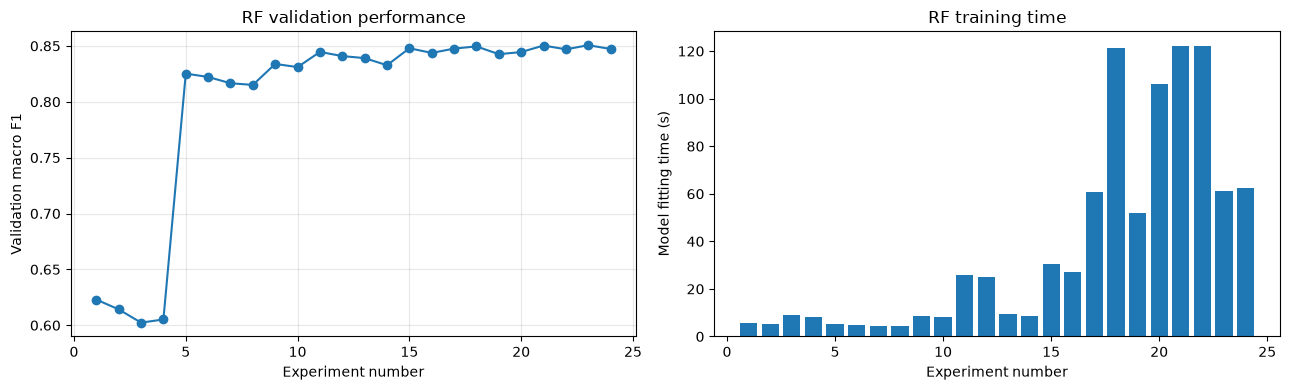

Seed stability comparison:


,representation,params,trial_ids,mean_val_macro_f1,std_val_macro_f1,mean_val_accuracy
0,colour_texture,"{'n_estimators': 400, 'max_depth': None, 'max_...","[668e7290f081, bb07e7d2b53e, a4870ec145cd]",0.848946,0.001776,0.853542
1,colour_texture,"{'n_estimators': 200, 'max_depth': None, 'max_...","[1e52287cbb11, 26a3f4d6407f, ed4f902ca10e]",0.848502,0.001855,0.853177


In [13]:
# Build the table directly from the trial records.
# No externally prepared CSV or PNG is required.
rf_records = records()

if not rf_records:
    raise RuntimeError("No RF trial records found. Run the RF search first.")

history_rf = pd.DataFrame([
    {
        **{k: v for k, v in record.items() if k != "params"},
        **record["params"],
    }
    for record in rf_records
])

history_rf = history_rf.sort_values(
    "finished_utc"
).reset_index(drop=True)

history_rf.insert(
    0,
    "experiment_number",
    np.arange(1, len(history_rf) + 1),
)

history_rf.to_csv(
    RUN / "experiment_history.csv",
    index=False,
)

columns_rf = [
    "experiment_number",
    "stage",
    "representation",
    "n_estimators",
    "max_depth",
    "max_features",
    "min_samples_leaf",
    "seed",
    "val_accuracy",
    "val_macro_f1",
    "fit_seconds",
    "val_predict_seconds",
]

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(history_rf[columns_rf].round(4))

# Plot validation performance and training time.
fig_rf, axes_rf = plt.subplots(1, 2, figsize=(13, 4))

axes_rf[0].plot(
    history_rf["experiment_number"],
    history_rf["val_macro_f1"],
    marker="o",
)
axes_rf[0].set_title("RF validation performance")
axes_rf[0].set_xlabel("Experiment number")
axes_rf[0].set_ylabel("Validation macro F1")
axes_rf[0].grid(alpha=0.3)

axes_rf[1].bar(
    history_rf["experiment_number"],
    history_rf["fit_seconds"],
)
axes_rf[1].set_title("RF training time")
axes_rf[1].set_xlabel("Experiment number")
axes_rf[1].set_ylabel("Model fitting time (s)")

fig_rf.tight_layout()
fig_rf.savefig(
    RUN / "optimization_history.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

print("Seed stability comparison:")
display(pd.DataFrame(
    json.loads((RUN / "seed_comparison.json").read_text())
))

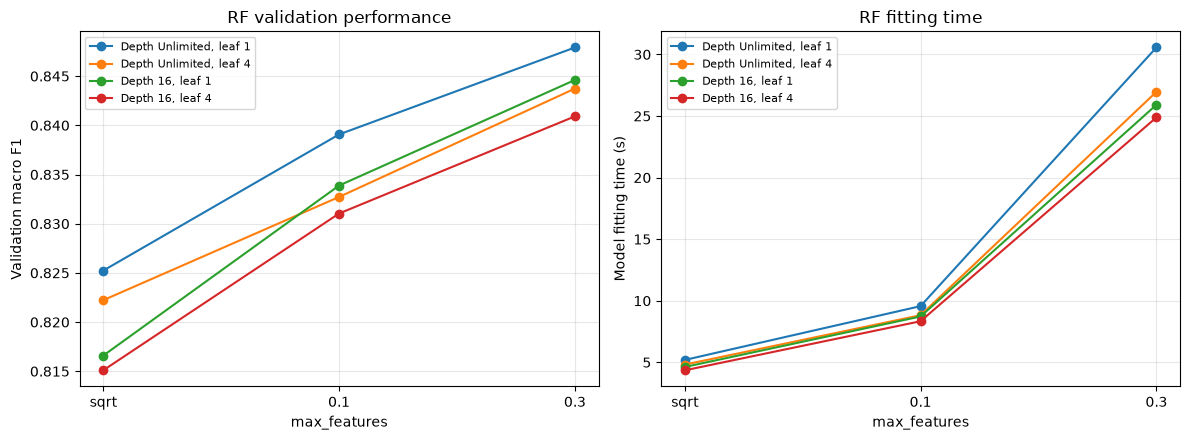

Saved figure: /Users/mbk/Downloads/5318/figures/rf_structural_tuning.png


In [37]:
# Generate the RF structural tuning figure from existing results.
from pathlib import Path
import matplotlib.pyplot as plt

rf_structure = history_rf.loc[
    (history_rf["representation"] == "colour_texture")
    & (history_rf["n_estimators"] == 100)
    & (history_rf["seed"] == 42)
].copy()

rf_structure["feature_rule"] = (
    rf_structure["max_features"].astype(str)
)
feature_rules = ["sqrt", "0.1", "0.3"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for depth in [None, 16]:
    for leaf in [1, 4]:
        depth_mask = (
            rf_structure["max_depth"].isna()
            if depth is None
            else rf_structure["max_depth"].eq(depth)
        )

        subset = rf_structure.loc[
            depth_mask
            & rf_structure["min_samples_leaf"].eq(leaf)
        ].copy()

        assert len(subset) == 3
        assert set(subset["feature_rule"]) == set(feature_rules)

        subset = subset.set_index("feature_rule").loc[feature_rules]
        depth_label = "Unlimited" if depth is None else "16"
        label = f"Depth {depth_label}, leaf {leaf}"

        for ax, metric in zip(
            axes, ["val_macro_f1", "fit_seconds"]
        ):
            ax.plot(
                range(3),
                subset[metric],
                marker="o",
                label=label,
            )

for ax in axes:
    ax.set_xticks(range(3))
    ax.set_xticklabels(feature_rules)
    ax.set_xlabel("max_features")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_title("RF validation performance")
axes[0].set_ylabel("Validation macro F1")
axes[1].set_title("RF fitting time")
axes[1].set_ylabel("Model fitting time (s)")

fig.tight_layout()

rf_figure_dir = Path("figures")
rf_figure_dir.mkdir(parents=True, exist_ok=True)
rf_figure_path = rf_figure_dir / "rf_structural_tuning.png"

fig.savefig(rf_figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", rf_figure_path.resolve())

### Fully connected neural network

In [14]:
# Compare three hyperparameters across eight configurations.
param_grid_mlp = {
    "hidden_units": [(128, 64), (256, 128)],
    "dropout_rate": [0.0, 0.2],
    "learning_rate": [0.001, 0.0003],
}

MAX_EPOCHS_MLP = 60
BATCH_SIZE_MLP = 128
PATIENCE_MLP = 8

configs_mlp = list(ParameterGrid(param_grid_mlp))
print("Number of configurations:", len(configs_mlp))

Number of configurations: 8


We use grid search to compare eight MLP configurations:
hidden-layer sizes (128, 64) or (256, 128), dropout 0.0 or 0.2,
and learning rate 0.001 or 0.0003. These settings vary model
capacity, regularisation and update size.

All configurations use the shared validation split, seed 42,
batch size 128 and a maximum of 60 epochs. Early stopping
monitors validation loss with patience 8 and restores the
best weights. We rank configurations by validation macro F1,
using accuracy to break ties, and record runtime and learning
curves for each trial.

In [15]:
results_mlp = []
histories_mlp = {}

for trial_id, config in enumerate(configs_mlp, start=1):
    # Start each configuration with a fresh model.
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_MLP)

    print(f"\nConfiguration {trial_id}/{len(configs_mlp)}: {config}")

    start_time = perf_counter()

    model_mlp = build_mlp(
        input_dim=X_fit_scaled_mlp.shape[1],
        num_classes=len(np.unique(y_train_all_mlp)),
        **config,
    )

    early_stopping_mlp = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PATIENCE_MLP,
        restore_best_weights=True,
    )

    history_mlp = model_mlp.fit(
        X_fit_scaled_mlp,
        y_fit_mlp,
        validation_data=(X_val_scaled_mlp, y_val_mlp),
        epochs=MAX_EPOCHS_MLP,
        batch_size=BATCH_SIZE_MLP,
        callbacks=[early_stopping_mlp],
        shuffle=True,
        verbose=0,
    )

    fit_seconds = perf_counter() - start_time

    # Evaluate the restored model on the validation set.
    val_probabilities = model_mlp.predict(
        X_val_scaled_mlp, verbose=0
    )
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_accuracy = accuracy_score(y_val_mlp, val_predictions)
    val_macro_f1 = f1_score(
        y_val_mlp,
        val_predictions,
        average="macro",
        zero_division=0,
    )

    best_epoch = int(
        np.argmin(history_mlp.history["val_loss"]) + 1
    )

    results_mlp.append({
        "trial": trial_id,
        **config,
        "best_epoch": best_epoch,
        "epochs_run": len(history_mlp.history["loss"]),
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "fit_seconds": fit_seconds,
    })

    # Keep learning curves for later plots.
    histories_mlp[trial_id] = history_mlp.history

    print(
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"Time: {fit_seconds:.1f}s"
    )

# Rank configurations by macro F1, then accuracy.
results_df_mlp = pd.DataFrame(results_mlp).sort_values(
    by=["val_macro_f1", "val_accuracy"],
    ascending=[False, False],
).reset_index(drop=True)

results_df_mlp.round(4)


Configuration 1/8: {'dropout_rate': 0.0, 'hidden_units': (128, 64), 'learning_rate': 0.001}
Validation accuracy: 0.8344 | Macro F1: 0.8311 | Time: 2.2s

Configuration 2/8: {'dropout_rate': 0.0, 'hidden_units': (128, 64), 'learning_rate': 0.0003}
Validation accuracy: 0.8419 | Macro F1: 0.8380 | Time: 3.8s

Configuration 3/8: {'dropout_rate': 0.0, 'hidden_units': (256, 128), 'learning_rate': 0.001}
Validation accuracy: 0.8348 | Macro F1: 0.8322 | Time: 3.0s

Configuration 4/8: {'dropout_rate': 0.0, 'hidden_units': (256, 128), 'learning_rate': 0.0003}
Validation accuracy: 0.8455 | Macro F1: 0.8407 | Time: 3.8s

Configuration 5/8: {'dropout_rate': 0.2, 'hidden_units': (128, 64), 'learning_rate': 0.001}
Validation accuracy: 0.8598 | Macro F1: 0.8547 | Time: 4.1s

Configuration 6/8: {'dropout_rate': 0.2, 'hidden_units': (128, 64), 'learning_rate': 0.0003}
Validation accuracy: 0.8620 | Macro F1: 0.8570 | Time: 8.7s

Configuration 7/8: {'dropout_rate': 0.2, 'hidden_units': (256, 128), 'learni

,trial,dropout_rate,hidden_units,learning_rate,best_epoch,epochs_run,val_accuracy,val_macro_f1,fit_seconds
0,8,0.2,"(256, 128)",0.0003,33,41,0.8661,0.8606,7.6841
1,7,0.2,"(256, 128)",0.0010,13,21,0.8622,0.8577,4.2389
2,6,0.2,"(128, 64)",0.0003,50,58,0.8620,0.8570,8.7124
3,5,0.2,"(128, 64)",0.0010,21,29,0.8598,0.8547,4.0793
4,4,0.0,"(256, 128)",0.0003,13,21,0.8455,0.8407,3.8134
5,2,0.0,"(128, 64)",0.0003,21,29,0.8419,0.8380,3.8224
6,3,0.0,"(256, 128)",0.0010,8,16,0.8348,0.8322,3.0189
7,1,0.0,"(128, 64)",0.0010,7,15,0.8344,0.8311,2.2482


In [16]:
# Save all MLP tuning results and learning histories.
MLP_RESULTS_DIR = ROOT / "merged_mlp_results"
MLP_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df_mlp.to_csv(
    MLP_RESULTS_DIR / "mlp_tuning_results.csv",
    index=False,
)

with (
    MLP_RESULTS_DIR / "mlp_learning_histories.json"
).open("w", encoding="utf-8") as file:
    json.dump(
        {
            str(trial): {
                metric: [float(value) for value in values]
                for metric, values in history.items()
            }
            for trial, history in histories_mlp.items()
        },
        file,
        indent=2,
    )

print("MLP tuning records saved to:", MLP_RESULTS_DIR)

MLP tuning records saved to: /Users/mbk/Downloads/5318/merged_mlp_results


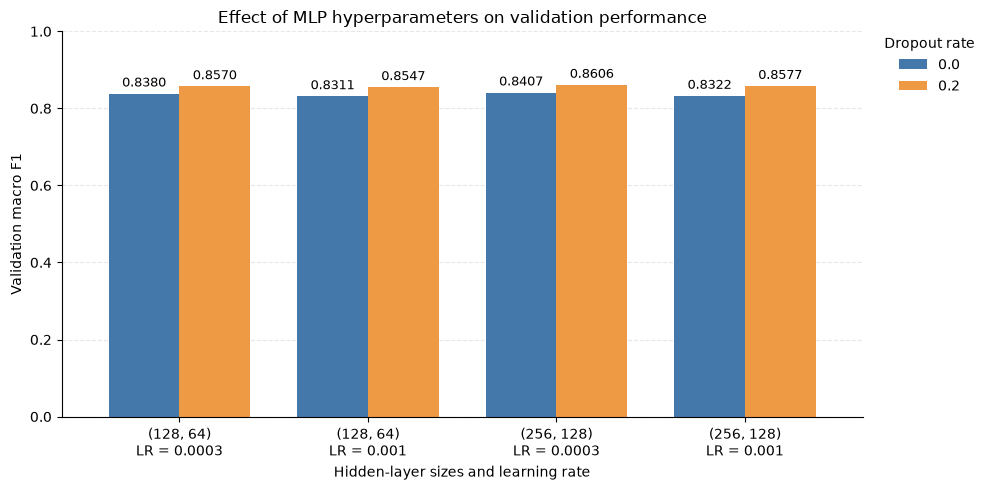

In [17]:
# Compare Dropout settings for each architecture and learning rate.
plot_data_mlp = results_df_mlp.copy()

plot_data_mlp["configuration"] = plot_data_mlp.apply(
    lambda row: (
        f"{row['hidden_units']}\n"
        f"LR = {row['learning_rate']:g}"
    ),
    axis=1,
)

comparison_mlp = plot_data_mlp.pivot(
    index="configuration",
    columns="dropout_rate",
    values="val_macro_f1",
).sort_index()

fig, ax = plt.subplots(figsize=(10, 5))

comparison_mlp.plot.bar(
    ax=ax,
    color=["#4477AA", "#EE9944"],
    width=0.75,
    rot=0,
)

# Display the exact validation scores above the bars.
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)

ax.set_title("Effect of MLP hyperparameters on validation performance")
ax.set_xlabel("Hidden-layer sizes and learning rate")
ax.set_ylabel("Validation macro F1")
ax.set_ylim(0, 1)
ax.legend(
    title="Dropout rate",
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0,
    frameon=False,
)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# Export a high-resolution figure for the report.
FIGURE_DIR_MLP = Path("figures")
FIGURE_DIR_MLP.mkdir(exist_ok=True)

fig.savefig(
    FIGURE_DIR_MLP / "mlp_hyperparameter_comparison.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

Trial 8 performed best among the eight configurations, with
validation macro F1 of 0.8606 and accuracy of 0.8661.
It used hidden layers of (256, 128), dropout 0.2 and
learning rate 0.0003.

Dropout improves validation macro F1 in all four matched comparisons in this search. The lower learning rate also performs better in each matched comparison, although it generally requires more training epochs. These findings are limited to the tested configurations and the single split and seed used.

The learning curves show a widening gap between training and validation performance. Training loss continues to decrease while validation loss largely plateaus, indicating overfitting. The lowest validation loss occurs at epoch 33, which determines the training duration for the final model.

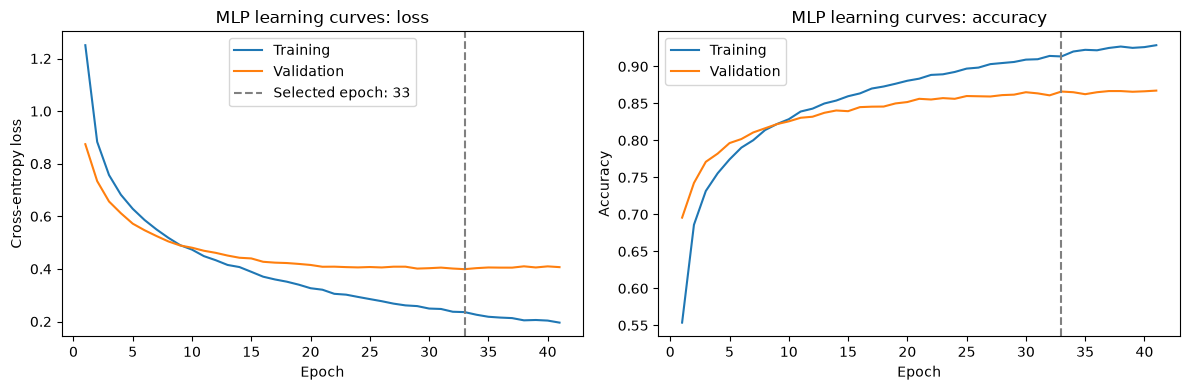

In [18]:
# Retrieve the learning history of the selected configuration.
best_trial_mlp = int(results_df_mlp.iloc[0]["trial"])
best_history_mlp = histories_mlp[best_trial_mlp]
best_epoch_mlp = int(results_df_mlp.iloc[0]["best_epoch"])

epochs_mlp = range(1, len(best_history_mlp["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training and validation loss
axes[0].plot(
    epochs_mlp, best_history_mlp["loss"], label="Training"
)
axes[0].plot(
    epochs_mlp, best_history_mlp["val_loss"], label="Validation"
)
axes[0].axvline(
    best_epoch_mlp, color="grey", linestyle="--",
    label=f"Selected epoch: {best_epoch_mlp}",
)
axes[0].set_title("MLP learning curves: loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

# Training and validation accuracy
axes[1].plot(
    epochs_mlp, best_history_mlp["accuracy"], label="Training"
)
axes[1].plot(
    epochs_mlp, best_history_mlp["val_accuracy"], label="Validation"
)
axes[1].axvline(
    best_epoch_mlp, color="grey", linestyle="--"
)
axes[1].set_title("MLP learning curves: accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### Convolutional neural network

In [19]:
# Compare three hyperparameters across eight configurations.
param_grid_cnn = {
    "base_filters": [16, 32],
    "dropout_rate": [0.0, 0.3],
    "learning_rate": [0.001, 0.0003],
}

MAX_EPOCHS_CNN = 30
BATCH_SIZE_CNN = 128
PATIENCE_CNN = 5

configs_cnn = list(ParameterGrid(param_grid_cnn))
print("Number of configurations:", len(configs_cnn))

Number of configurations: 8


We evaluate eight configurations by varying three hyperparameters:

- **Base filters** (16 or 32). The second and third convolutional
  blocks use twice and four times this number. More filters
  increase model capacity and computational cost.
- **Dropout rate** (0.0 or 0.3). Dropout randomly sets a proportion
  of activations to zero during training and can help reduce
  overfitting.
- **Learning rate** (0.001 or 0.0003). This controls the scale
  of Adam's parameter updates. A smaller value may require
  more epochs, while a larger value may make training less stable.

We use grid search on the shared validation split to keep the
experiment manageable. Five-fold cross-validation would require
five fits per configuration. Using the same split also keeps
the validation samples consistent across the three models.

All configurations use seed 42, a batch size of 128 and a maximum
of 30 epochs. Early stopping monitors validation loss with a
patience of five epochs and restores the weights with the lowest
validation loss. We rank configurations by validation macro F1,
using accuracy to break ties.

The recorded fitting times include training and validation
within model.fit, but exclude preprocessing, model construction,
the separate validation prediction step, plotting and file export.

In [20]:
results_cnn = []
histories_cnn = {}

for trial_id, config in enumerate(configs_cnn, start=1):
    # Start each configuration with a fresh model.
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED_CNN)

    print(f"\nConfiguration {trial_id}/{len(configs_cnn)}: {config}", flush=True)

    model_cnn = build_cnn(
        input_shape=INPUT_SHAPE_CNN,
        num_classes=NUM_CLASSES_CNN,
        **config,
    )

    early_stopping_cnn = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=PATIENCE_CNN,
        restore_best_weights=True,
    )

    start_time = perf_counter()

    history_cnn = model_cnn.fit(
        X_fit_cnn,
        y_fit_cnn,
        validation_data=(X_val_cnn, y_val_cnn),
        epochs=MAX_EPOCHS_CNN,
        batch_size=BATCH_SIZE_CNN,
        callbacks=[early_stopping_cnn],
        shuffle=True,
        verbose=0,
    )

    fit_seconds = perf_counter() - start_time

    # Evaluate the restored (best-epoch) model on the validation set.
    val_probabilities = model_cnn.predict(X_val_cnn, batch_size=512, verbose=0)
    val_predictions = np.argmax(val_probabilities, axis=1)

    val_accuracy = accuracy_score(y_val_cnn, val_predictions)
    val_macro_f1 = f1_score(
        y_val_cnn, val_predictions, average="macro", zero_division=0,
    )

    best_epoch = int(np.argmin(history_cnn.history["val_loss"]) + 1)
    epochs_run = len(history_cnn.history["loss"])

    results_cnn.append({
        "trial": trial_id,
        **config,
        "n_params": model_cnn.count_params(),
        "best_epoch": best_epoch,
        "epochs_run": epochs_run,
        "train_accuracy_at_best": history_cnn.history["accuracy"][best_epoch - 1],
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "fit_seconds": fit_seconds,
        "seconds_per_epoch": fit_seconds / epochs_run,
    })

    # Keep learning curves for later plots.
    histories_cnn[trial_id] = history_cnn.history

    print(
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"Macro F1: {val_macro_f1:.4f} | "
        f"Best epoch: {best_epoch}/{epochs_run} | "
        f"Time: {fit_seconds:.1f}s",
        flush=True,
    )

# Rank configurations by macro F1, then accuracy.
results_df_cnn = pd.DataFrame(results_cnn).sort_values(
    by=["val_macro_f1", "val_accuracy"],
    ascending=[False, False],
).reset_index(drop=True)

results_df_cnn.round(4)


Configuration 1/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.001}
Validation accuracy: 0.8667 | Macro F1: 0.8637 | Best epoch: 14/19 | Time: 30.6s

Configuration 2/8: {'base_filters': 16, 'dropout_rate': 0.0, 'learning_rate': 0.0003}
Validation accuracy: 0.8516 | Macro F1: 0.8477 | Best epoch: 30/30 | Time: 46.3s

Configuration 3/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Validation accuracy: 0.8955 | Macro F1: 0.8937 | Best epoch: 28/30 | Time: 48.9s

Configuration 4/8: {'base_filters': 16, 'dropout_rate': 0.3, 'learning_rate': 0.0003}
Validation accuracy: 0.8309 | Macro F1: 0.8278 | Best epoch: 28/30 | Time: 48.9s

Configuration 5/8: {'base_filters': 32, 'dropout_rate': 0.0, 'learning_rate': 0.001}
Validation accuracy: 0.8722 | Macro F1: 0.8685 | Best epoch: 9/14 | Time: 50.3s

Configuration 6/8: {'base_filters': 32, 'dropout_rate': 0.0, 'learning_rate': 0.0003}
Validation accuracy: 0.8381 | Macro F1: 0.8339 | Best epoch: 13/18 | Time: 65

,trial,base_filters,dropout_rate,learning_rate,n_params,best_epoch,epochs_run,train_accuracy_at_best,val_accuracy,val_macro_f1,fit_seconds,seconds_per_epoch
0,7,32,0.3,0.0010,241993,29,30,0.9375,0.9367,0.9354,112.4792,3.7493
1,3,16,0.3,0.0010,98601,28,30,0.8868,0.8955,0.8937,48.9078,1.6303
2,8,32,0.3,0.0003,241993,28,30,0.8880,0.8939,0.8927,113.3721,3.7791
3,5,32,0.0,0.0010,241993,9,14,0.9252,0.8722,0.8685,50.3424,3.5959
4,1,16,0.0,0.0010,98601,14,19,0.9096,0.8667,0.8637,30.6460,1.6129
5,2,16,0.0,0.0003,98601,30,30,0.9060,0.8516,0.8477,46.3382,1.5446
6,6,32,0.0,0.0003,241993,13,18,0.8755,0.8381,0.8339,65.1579,3.6199
7,4,16,0.3,0.0003,98601,28,30,0.8311,0.8309,0.8278,48.9339,1.6311


In [21]:
# Save the search results and learning curves for the group's tables and plots.
results_df_cnn.to_csv(RESULTS_DIR_CNN / "cnn_tuning_results.csv", index=False)

history_rows_cnn = [
    {"trial": trial_id, "epoch": epoch + 1,
     **{metric: values[epoch] for metric, values in history.items()}}
    for trial_id, history in histories_cnn.items()
    for epoch in range(len(history["loss"]))
]
pd.DataFrame(history_rows_cnn).to_csv(
    RESULTS_DIR_CNN / "cnn_tuning_histories.csv", index=False
)

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("cnn_tuning_*.csv")))

Saved: ['cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


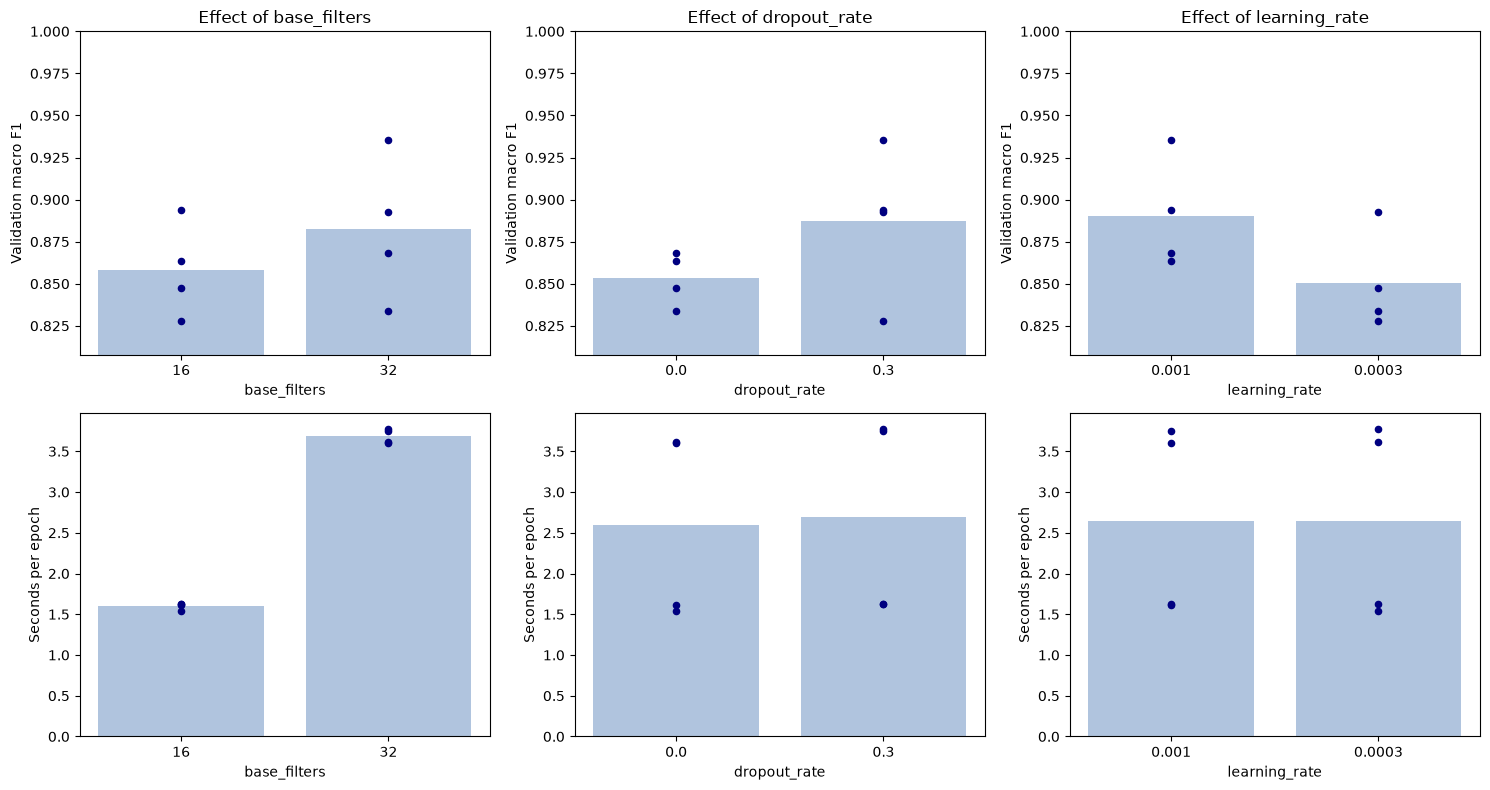

In [22]:
# Effect of each hyperparameter: mean over the four configurations sharing a value,
# with the individual configurations shown as points.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, name in enumerate(param_grid_cnn):
    values = param_grid_cnn[name]
    labels = [str(value) for value in values]

    for row, (metric, ylabel) in enumerate([
        ("val_macro_f1", "Validation macro F1"),
        ("seconds_per_epoch", "Seconds per epoch"),
    ]):
        ax = axes[row, col]
        groups = [results_df_cnn.loc[results_df_cnn[name] == value, metric] for value in values]
        ax.bar(labels, [group.mean() for group in groups], color="lightsteelblue", label="Mean")
        for position, group in enumerate(groups):
            ax.scatter([position] * len(group), group, color="navy", zorder=3, s=20)
        ax.set_xlabel(name)
        ax.set_ylabel(ylabel)

    low = results_df_cnn["val_macro_f1"].min()
    axes[0, col].set_ylim(low - 0.02, 1.0)
    axes[0, col].set_title(f"Effect of {name}")

plt.tight_layout()
plt.show()

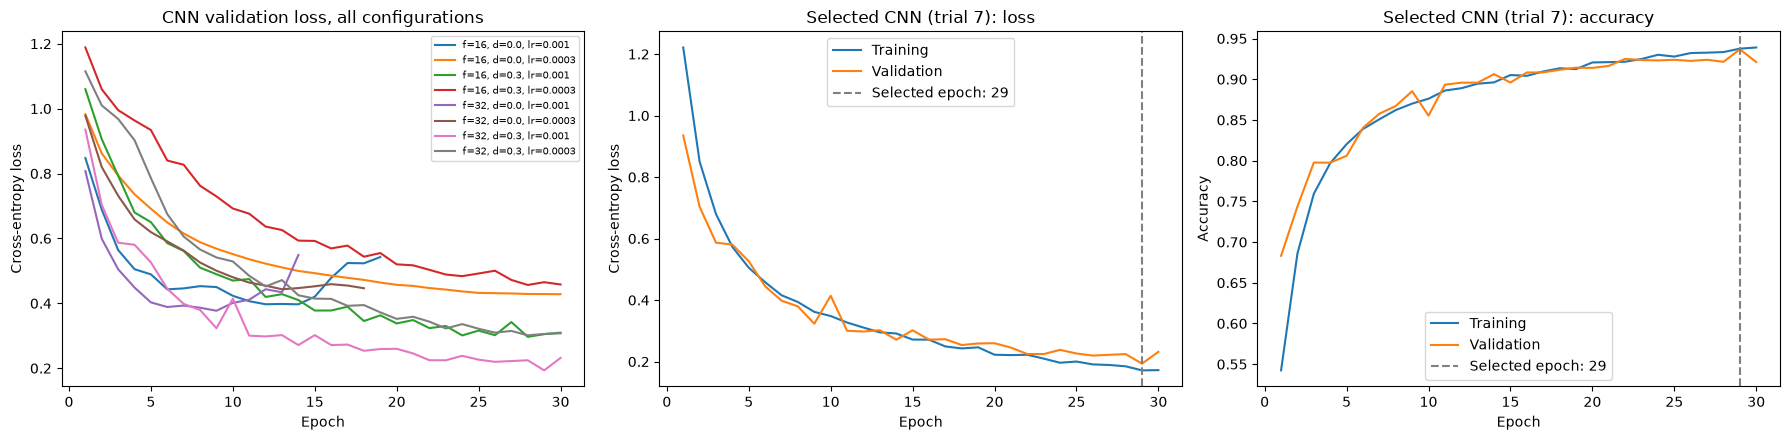

In [ ]:
# Validation loss of every configuration, and the learning curves of the selected one.
best_trial_cnn = int(results_df_cnn.iloc[0]["trial"])
best_epoch_cnn = int(results_df_cnn.iloc[0]["best_epoch"])
best_history_cnn = histories_cnn[best_trial_cnn]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for _, row in results_df_cnn.sort_values("trial").iterrows():
    history = histories_cnn[int(row["trial"])]
    axes[0].plot(
        range(1, len(history["val_loss"]) + 1), history["val_loss"],
        label=(f"f={int(row['base_filters'])}, d={row['dropout_rate']}, "
               f"lr={row['learning_rate']}"),
    )
axes[0].set_title("CNN validation loss, all configurations")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend(fontsize=7)

epochs_cnn = range(1, len(best_history_cnn["loss"]) + 1)
for ax, metric, ylabel in [
    (axes[1], "loss", "Cross-entropy loss"),
    (axes[2], "accuracy", "Accuracy"),
]:
    ax.plot(epochs_cnn, best_history_cnn[metric], label="Training")
    ax.plot(epochs_cnn, best_history_cnn[f"val_{metric}"], label="Validation")
    ax.axvline(best_epoch_cnn, color="grey", linestyle="--",
               label=f"Selected epoch: {best_epoch_cnn}")
    ax.set_title(f"Selected CNN (trial {best_trial_cnn}): {metric}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()

plt.tight_layout()
fig.savefig(
    RESULTS_DIR_CNN / "cnn_learning_curves.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In this run, trial 7 achieved the highest
validation macro F1 (0.9354) and accuracy (0.9367). It used
32 base filters, dropout 0.3, and learning rate 0.001.
Its lowest validation loss occurred at epoch 29 of 30,
which determines the final training duration.

Learning rate 0.001 outperformed 0.0003 in all four matched
comparisons. Three of the four lower-learning-rate configurations
reached the 30-epoch limit, with their lowest validation loss
at epochs 28–30. The remaining configuration (trial 6) stopped
after 18 epochs, with its lowest validation loss at epoch 13.
A longer training budget could change the comparison for
configurations that reached the epoch limit.

Dropout improved validation macro F1 in three of four
matched comparisons. The exception was 16 base filters
with learning rate 0.0003.

Increasing the base filters from 16 to 32 improved macro F1
by approximately 0.0417 and 0.0648 with dropout, at learning
rates 0.001 and 0.0003 respectively. Without dropout, the
corresponding changes were +0.0048 and −0.0138. The benefit
of additional filters therefore depended on the other settings.

The selected model reached its lowest validation loss near
the epoch limit. This suggests that further improvement with
a larger training budget is possible, but has not been tested.
Training curves were recorded with dropout enabled, whereas
validation used inference mode, so their gap should be
interpreted cautiously.

These findings are limited to the tested configurations,
one validation split, and one random seed.

## 4. Final models

We retrain each model on all 32,000 training samples using
the settings selected during validation, then evaluate it on
the 8,000 test samples. The settings are specified explicitly,
so these cells do not depend on running Section 3.

The recorded runtimes cover different steps:

- RF fitting and prediction times exclude feature extraction,
  which is timed separately.
- MLP training time includes standardisation, model construction
  and fitting. Test time includes standardisation and prediction.
  Feature extraction is timed separately for both.
- CNN training time includes image preprocessing, model
  construction and fitting. Test time includes preprocessing
  and prediction.

These differences need to be considered when comparing runtimes.
The timings describe the implementations used in this experiment,
rather than a controlled comparison of algorithm speed.

### Algorithm of choice from first six weeks of course

The final RF uses the configuration selected in the original
validation experiments: colour_texture features, 400 trees,
unrestricted depth, max_features=0.3, and min_samples_leaf=1.

The code below fits a fresh model on all training samples and
evaluates it on the provided test set. It requires the setup
cells but does not depend on running the hyperparameter search.
Each execution writes results to a new directory.

A preliminary RF experiment had already inspected this test
set. Therefore, this evaluation is not the first inspection of
a completely unseen test set. Test results are not used to
revise the configuration.

{"timestamp_utc": "2026-10-29T00:34:14.364462+00:00", "event": "final_completed", "test_accuracy": 0.86075, "test_macro_f1": 0.8564919764778287, "train_samples": 32000, "test_samples": 8000, "fit_seconds": 163.31210566597292, "predict_seconds": 0.07672229199670255, "train_feature_seconds": 2.6339258330408484, "test_feature_seconds": 0.6260737089905888}


,test_accuracy,test_macro_f1,train_samples,test_samples,fit_seconds,predict_seconds,train_feature_seconds,test_feature_seconds,test_weighted_f1
0,0.86075,0.856492,32000,8000,163.312106,0.076722,2.633926,0.626074,0.85968


,precision,recall,f1-score,support
0,0.979475,0.983963,0.981714,873.00000
1,0.992958,0.986014,0.989474,858.00000
2,0.841530,0.702395,0.765693,877.00000
3,0.944690,0.934354,0.939494,914.00000
4,0.812887,0.890095,0.849741,737.00000
5,0.840145,0.862873,0.851358,1072.00000
6,0.787066,0.731672,0.758359,682.00000
7,0.729662,0.717097,0.723325,813.00000
8,0.809892,0.892675,0.849271,1174.00000
accuracy,0.860750,0.860750,0.860750,0.86075


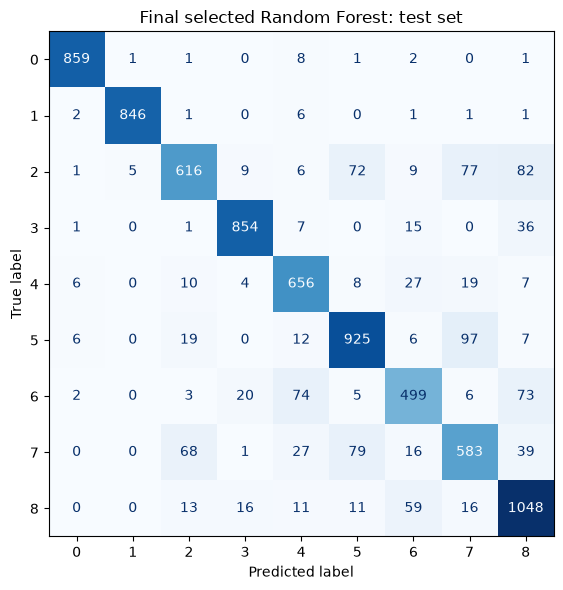

RF final results saved to: /Users/mbk/Downloads/5318/merged_rf_final_20261029_003126_442901


In [24]:
# Explicit configuration from the original validation search.
FINAL_CONFIG_RF = {
    "representation": "colour_texture",
    "params": {
        "n_estimators": 400,
        "max_depth": None,
        "max_features": 0.3,
        "min_samples_leaf": 1,
    },
}

# Use a fresh directory so this cell actually fits the model
# instead of silently displaying cached final results.
search_run_rf = RUN

RUN = ROOT / (
    "merged_rf_final_"
    + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
)

try:
    final_metrics_rf = final_evaluation(FINAL_CONFIG_RF)

    report_rf = pd.read_csv(
        RUN / "final" / "classification_report.csv",
        index_col=0,
    )

    final_metrics_rf["test_weighted_f1"] = float(
        report_rf.loc["weighted avg", "f1-score"]
    )

    dump(
        RUN / "final" / "metrics.json",
        final_metrics_rf,
    )

    display(pd.DataFrame([final_metrics_rf]))
    display(report_rf)

    cm_rf = np.load(
        RUN / "final" / "confusion_matrix.npy",
        allow_pickle=False,
    )

    fig_rf_final, ax_rf_final = plt.subplots(figsize=(7, 6))

    ConfusionMatrixDisplay(
        confusion_matrix=cm_rf,
        display_labels=report_rf.index[:cm_rf.shape[0]],
    ).plot(
        ax=ax_rf_final,
        cmap="Blues",
        colorbar=False,
        values_format="d",
    )

    ax_rf_final.set_title("Final selected Random Forest: test set")
    fig_rf_final.tight_layout()

    fig_rf_final.savefig(
        RUN / "final" / "rf_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    print("RF final results saved to:", RUN)

finally:
    RUN = search_run_rf

### Fully connected neural network

In [25]:
# Configuration selected using validation macro F1.
FINAL_CONFIG_MLP = {
    "hidden_units": (256, 128),
    "dropout_rate": 0.2,
    "learning_rate": 0.0003,
}
FINAL_EPOCHS_MLP = 33
FINAL_BATCH_SIZE_MLP = 128

keras.backend.clear_session()
keras.utils.set_random_seed(SEED_MLP)

start_time_mlp = perf_counter()

# Refit preprocessing on the complete training set.
final_scaler_mlp = StandardScaler()
X_train_final_mlp = final_scaler_mlp.fit_transform(
    X_train_all_mlp
).astype("float32")

# Train a fresh model using all training samples.
final_model_mlp = build_mlp(
    input_dim=X_train_final_mlp.shape[1],
    num_classes=len(np.unique(y_train_all_mlp)),
    **FINAL_CONFIG_MLP,
)

final_history_mlp = final_model_mlp.fit(
    X_train_final_mlp,
    y_train_all_mlp,
    epochs=FINAL_EPOCHS_MLP,
    batch_size=FINAL_BATCH_SIZE_MLP,
    shuffle=True,
    verbose=0,
)

final_fit_seconds_mlp = perf_counter() - start_time_mlp

print("Final configuration:", FINAL_CONFIG_MLP)
print("Training samples:", len(y_train_all_mlp))
print("Training epochs:", FINAL_EPOCHS_MLP)
print(
    f"Preprocessing and training time: "
    f"{final_fit_seconds_mlp:.2f}s"
)

Final configuration: {'hidden_units': (256, 128), 'dropout_rate': 0.2, 'learning_rate': 0.0003}
Training samples: 32000
Training epochs: 33
Preprocessing and training time: 6.59s


In [26]:
# Load original test images only for final evaluation.
test_images_mlp = np.load(
    DATA / "X_test.npy", allow_pickle=False
)
y_test_mlp = np.load(
    DATA / "y_test.npy", allow_pickle=False
).astype("int64").ravel()

# Apply the same fixed feature extraction as for training.
feature_start_mlp = perf_counter()

X_test_mlp = features(test_images_mlp, "colour_texture")

test_feature_seconds_mlp = perf_counter() - feature_start_mlp

print(
    f"Test feature extraction time: "
    f"{test_feature_seconds_mlp:.2f}s"
)

start_time_mlp = perf_counter()

# Apply preprocessing learned from the complete training set.
X_test_scaled_mlp = final_scaler_mlp.transform(
    X_test_mlp
).astype("float32")

test_probabilities_mlp = final_model_mlp.predict(
    X_test_scaled_mlp, verbose=0
)
test_predictions_mlp = np.argmax(
    test_probabilities_mlp, axis=1
)

test_predict_seconds_mlp = perf_counter() - start_time_mlp

test_accuracy_mlp = accuracy_score(
    y_test_mlp, test_predictions_mlp
)
test_macro_f1_mlp = f1_score(
    y_test_mlp, test_predictions_mlp,
    average="macro", zero_division=0,
)
test_weighted_f1_mlp = f1_score(
    y_test_mlp, test_predictions_mlp,
    average="weighted", zero_division=0,
)

print(f"Test accuracy: {test_accuracy_mlp:.4f}")
print(f"Test macro F1: {test_macro_f1_mlp:.4f}")
print(f"Test weighted F1: {test_weighted_f1_mlp:.4f}")
print(
    f"Test preprocessing and prediction time: "
    f"{test_predict_seconds_mlp:.2f}s"
)

print("\nClassification report:")
print(classification_report(
    y_test_mlp,
    test_predictions_mlp,
    digits=4,
    zero_division=0,
))

Test feature extraction time: 0.63s
Test accuracy: 0.8772
Test macro F1: 0.8737
Test weighted F1: 0.8770
Test preprocessing and prediction time: 0.09s

Classification report:
              precision    recall  f1-score   support

           0     0.9577    0.9863    0.9718       873
           1     0.9860    0.9872    0.9866       858
           2     0.8486    0.7412    0.7912       877
           3     0.9626    0.9573    0.9600       914
           4     0.8552    0.8738    0.8644       737
           5     0.8810    0.8498    0.8651      1072
           6     0.7762    0.8035    0.7896       682
           7     0.7337    0.7761    0.7543       813
           8     0.8657    0.8952    0.8802      1174

    accuracy                         0.8772      8000
   macro avg     0.8741    0.8745    0.8737      8000
weighted avg     0.8779    0.8772    0.8770      8000



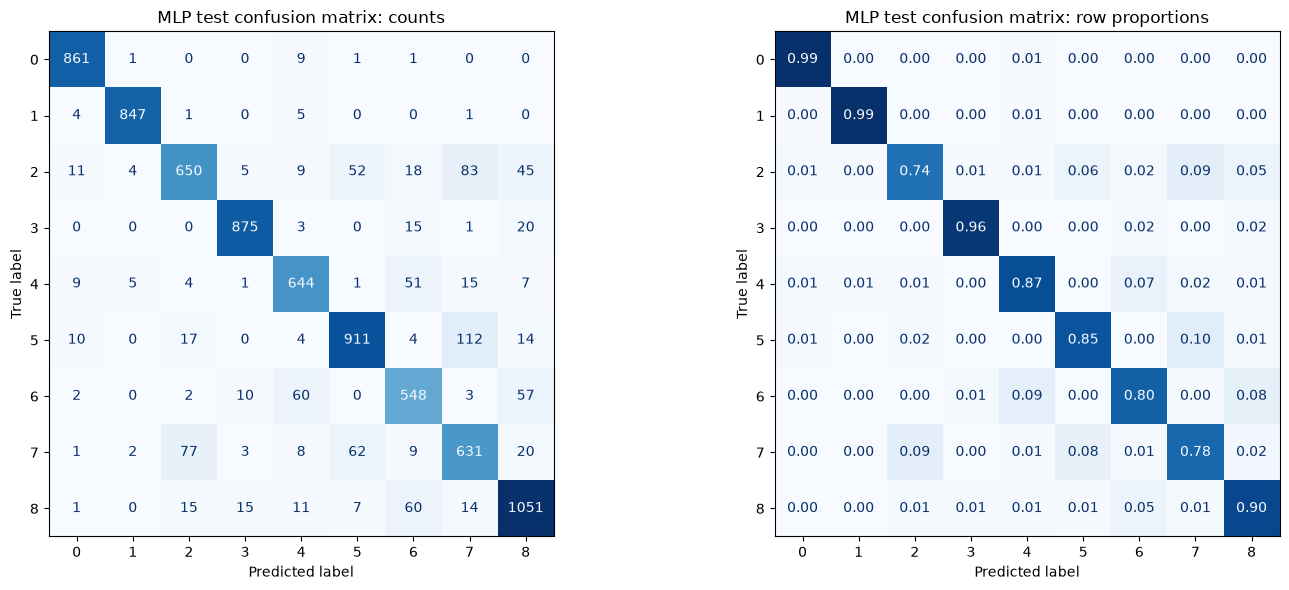

In [27]:
# Display counts and recall-normalised confusion matrices.
class_labels_mlp = np.unique(y_train_all_mlp)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_mlp,
    test_predictions_mlp,
    labels=class_labels_mlp,
    display_labels=class_labels_mlp,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("MLP test confusion matrix: counts")

ConfusionMatrixDisplay.from_predictions(
    y_test_mlp,
    test_predictions_mlp,
    labels=class_labels_mlp,
    display_labels=class_labels_mlp,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    colorbar=False,
    ax=axes[1],
)
axes[1].set_title("MLP test confusion matrix: row proportions")

plt.tight_layout()
plt.show()

The final MLP is retrained from scratch on all 32,000 training samples for 33 epochs using the selected configuration. Standardisation is refitted on the complete training set and then applied to the test set. The final training and evaluation cells use explicitly specified settings and do not depend on executing the tuning cells.

On the 8,000 test samples, the model achieves accuracy of
0.8772, macro F1 of 0.8737, and weighted F1 of 0.8770.
Standardisation, model construction and fitting take
6.59 seconds, while test standardisation and prediction
take 0.09 seconds on the local machine. These times
exclude feature extraction, which is measured separately.

Performance varies across classes. Classes 0, 1, and 3 have F1 scores of approximately 0.96 or
higher, whereas class 7 has the lowest F1 score (0.7543). The confusion matrix shows that 112 class-5 samples are predicted as class 7, while classes 2 and 7 are confused in both directions (83 and 77 samples, respectively). These errors indicate that the model does not separate all classes equally well using the extracted features. Test results are reported for final evaluation and are not used to revise the selected configuration.

### Convolutional neural network

The final CNN uses 32 base filters, dropout 0.3, and learning
rate 0.001, selected by validation macro F1. It is trained
from scratch on all 32,000 training images for 29 epochs,
the epoch with the lowest validation loss in the selected trial.

Channel means and standard deviations are recomputed on the
complete training set. These statistics are then applied to
the test images.

The final settings are specified explicitly, so training
requires the setup, data preprocessing functions, and network
definition, but does not require executing the tuning cells.
Test results are not used to revise the configuration.

In [28]:
# Configuration selected using validation macro F1 (Section 3).
FINAL_CONFIG_CNN = {
    "base_filters": 32,
    "dropout_rate": 0.3,
    "learning_rate": 0.001,
}
FINAL_EPOCHS_CNN = 29
FINAL_BATCH_SIZE_CNN = 128

In [29]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED_CNN)

start_time_cnn = perf_counter()

# Refit the channel statistics on the complete training set and preprocess it.
final_channel_mean_cnn, final_channel_std_cnn = fit_channel_stats_cnn(X_train_all_cnn)
X_train_final_cnn = preprocess_cnn(
    X_train_all_cnn, final_channel_mean_cnn, final_channel_std_cnn
)

# Train a fresh model using all training samples.
final_model_cnn = build_cnn(
    input_shape=INPUT_SHAPE_CNN,
    num_classes=NUM_CLASSES_CNN,
    **FINAL_CONFIG_CNN,
)

final_history_cnn = final_model_cnn.fit(
    X_train_final_cnn,
    y_train_all_cnn,
    epochs=FINAL_EPOCHS_CNN,
    batch_size=FINAL_BATCH_SIZE_CNN,
    shuffle=True,
    verbose=0,
)

final_fit_seconds_cnn = perf_counter() - start_time_cnn

print("Final configuration:", FINAL_CONFIG_CNN)
print("Trainable parameters:", final_model_cnn.count_params())
print("Training samples:", len(y_train_all_cnn))
print("Training epochs:", FINAL_EPOCHS_CNN)
print(f"Preprocessing and training time: {final_fit_seconds_cnn:.2f}s "
      f"({final_fit_seconds_cnn / FINAL_EPOCHS_CNN:.1f}s per epoch)")

Final configuration: {'base_filters': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001}
Trainable parameters: 241993
Training samples: 32000
Training epochs: 29
Preprocessing and training time: 127.74s (4.4s per epoch)


The average time per epoch shown above is the total preprocessing,
model construction and fitting time divided by 29 epochs.
It includes one-off setup costs and is not a separate measurement
of training time for each epoch. The same definition applies to
seconds_per_epoch in the final CNN results table.

In [30]:
# Load the same original test data used by RF and MLP.
X_test_img_cnn = np.load(
    DATA / "X_test.npy",
    allow_pickle=False,
)

y_test_cnn = np.load(
    DATA / "y_test.npy",
    allow_pickle=False,
).astype("int64").ravel()

assert X_test_img_cnn.shape[1:] == INPUT_SHAPE_CNN
assert len(X_test_img_cnn) == len(y_test_cnn)

print("CNN test images:", X_test_img_cnn.shape)
print("CNN test labels:", y_test_cnn.shape)

CNN test images: (8000, 28, 28, 3)
CNN test labels: (8000,)


In [31]:
start_time_cnn = perf_counter()

# Apply the training-set channel statistics to the held-out test images.
X_test_cnn = preprocess_cnn(
    X_test_img_cnn, final_channel_mean_cnn, final_channel_std_cnn
)

test_probabilities_cnn = final_model_cnn.predict(X_test_cnn, batch_size=512, verbose=0)
test_predictions_cnn = np.argmax(test_probabilities_cnn, axis=1)

test_predict_seconds_cnn = perf_counter() - start_time_cnn

test_metrics_cnn = {
    "accuracy": accuracy_score(y_test_cnn, test_predictions_cnn),
    "macro_f1": f1_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test_cnn, test_predictions_cnn, average="weighted", zero_division=0),
    "macro_precision": precision_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test_cnn, test_predictions_cnn, average="macro", zero_division=0),
}

for name, value in test_metrics_cnn.items():
    print(f"Test {name.replace('_', ' ')}: {value:.4f}")
print(f"Test preprocessing and prediction time: {test_predict_seconds_cnn:.2f}s")

print("\nClassification report:")
print(classification_report(
    y_test_cnn,
    test_predictions_cnn,
    target_names=[f"{i} {name}" for i, name in enumerate(CLASS_NAMES_CNN)],
    digits=4,
    zero_division=0,
))

Test accuracy: 0.9319
Test macro f1: 0.9303
Test weighted f1: 0.9316
Test macro precision: 0.9341
Test macro recall: 0.9296
Test preprocessing and prediction time: 0.41s

Classification report:
                                    precision    recall  f1-score   support

                         0 adipose     0.9863    0.9908    0.9886       873
                      1 background     0.9930    0.9918    0.9924       858
                          2 debris     0.7913    0.9384    0.8586       877
                     3 lymphocytes     0.9618    0.9923    0.9768       914
                           4 mucus     0.9537    0.9213    0.9372       737
                   5 smooth muscle     0.9246    0.9375    0.9310      1072
             6 normal colon mucosa     0.9396    0.9120    0.9256       682
            7 cancer-assoc. stroma     0.9041    0.7540    0.8223       813
8 colorectal adenocarcinoma epith.     0.9528    0.9284    0.9405      1174

                          accuracy          

In [32]:
# Export the final CNN results as CSV files for the combined comparison tables.
final_summary_cnn = pd.DataFrame([{
    "model": "CNN",
    "best_hyperparameters": "; ".join(f"{k}={v}" for k, v in FINAL_CONFIG_CNN.items()),
    "epochs": FINAL_EPOCHS_CNN,
    "batch_size": FINAL_BATCH_SIZE_CNN,
    "n_params": final_model_cnn.count_params(),
    "train_samples": len(y_train_all_cnn),
    "train_seconds": final_fit_seconds_cnn,
    "seconds_per_epoch": final_fit_seconds_cnn / FINAL_EPOCHS_CNN,
    "test_predict_seconds": test_predict_seconds_cnn,
    **{f"test_{name}": value for name, value in test_metrics_cnn.items()},
}])
final_summary_cnn.to_csv(RESULTS_DIR_CNN / "cnn_final_results.csv", index=False)

report_cnn = pd.DataFrame(classification_report(
    y_test_cnn, test_predictions_cnn, output_dict=True, zero_division=0,
)).T
per_class_cnn = report_cnn.iloc[:NUM_CLASSES_CNN].copy()
per_class_cnn.insert(0, "class_name", CLASS_NAMES_CNN)
per_class_cnn.index.name = "class_id"
per_class_cnn.to_csv(RESULTS_DIR_CNN / "cnn_classification_report.csv")

confusion_cnn = confusion_matrix(y_test_cnn, test_predictions_cnn, labels=range(NUM_CLASSES_CNN))
pd.DataFrame(
    confusion_cnn,
    index=[f"true_{i}" for i in range(NUM_CLASSES_CNN)],
    columns=[f"pred_{i}" for i in range(NUM_CLASSES_CNN)],
).to_csv(RESULTS_DIR_CNN / "cnn_confusion_matrix.csv")

pd.DataFrame({
    "y_true": y_test_cnn,
    "y_pred": test_predictions_cnn,
    "confidence": test_probabilities_cnn.max(axis=1),
}).to_csv(RESULTS_DIR_CNN / "cnn_test_predictions.csv", index_label="test_index")

print("Saved:", sorted(path.name for path in RESULTS_DIR_CNN.glob("*.csv")))
final_summary_cnn.round(4).T

Saved: ['cnn_classification_report.csv', 'cnn_confusion_matrix.csv', 'cnn_final_results.csv', 'cnn_test_predictions.csv', 'cnn_top_confusions.csv', 'cnn_tuning_histories.csv', 'cnn_tuning_results.csv']


,0
model,CNN
best_hyperparameters,base_filters=32; dropout_rate=0.3; learning_ra...
epochs,29
batch_size,128
n_params,241993
train_samples,32000
train_seconds,127.7435
seconds_per_epoch,4.4049
test_predict_seconds,0.4063
test_accuracy,0.9319


#### CNN error analysis

We examine class-level performance, confusion counts,
prediction confidence, and examples of misclassified images.
These analyses describe the final model and are not used
to revise its hyperparameters.

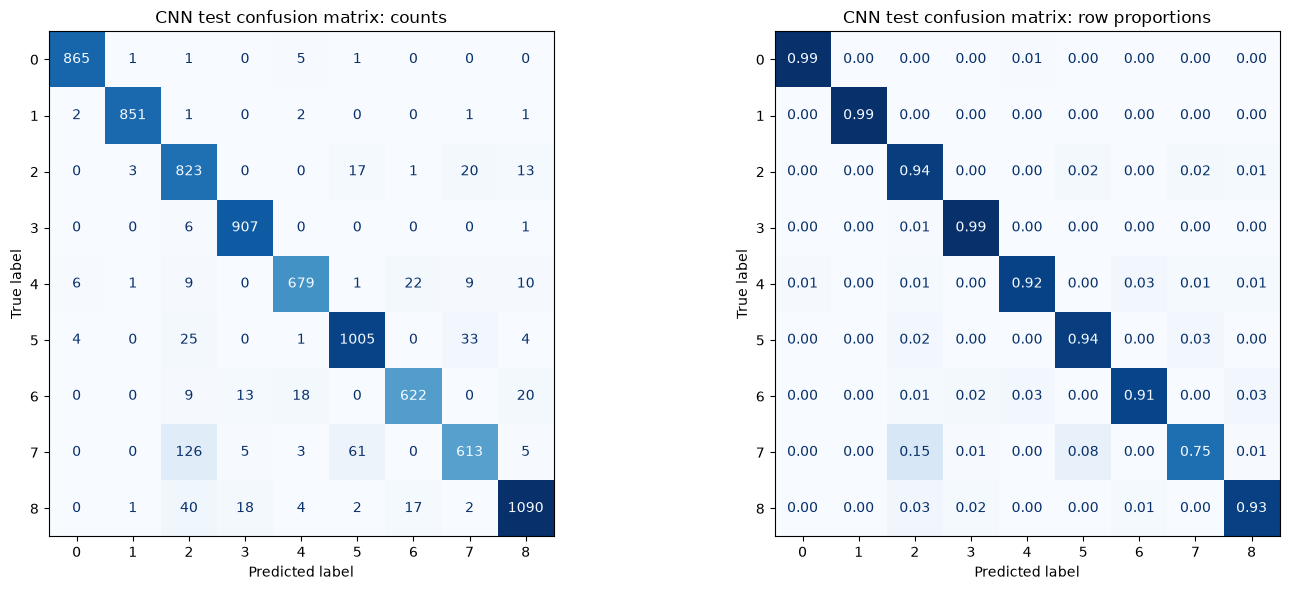

Class IDs: 0 = adipose, 1 = background, 2 = debris, 3 = lymphocytes, 4 = mucus, 5 = smooth muscle, 6 = normal colon mucosa, 7 = cancer-assoc. stroma, 8 = colorectal adenocarcinoma epith.


In [33]:
# Display counts and recall-normalised confusion matrices.
short_names_cnn = [f"{i}" for i in range(NUM_CLASSES_CNN)]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    cmap="Blues", values_format="d", colorbar=False, ax=axes[0],
)
axes[0].set_title("CNN test confusion matrix: counts")

ConfusionMatrixDisplay.from_predictions(
    y_test_cnn, test_predictions_cnn,
    labels=range(NUM_CLASSES_CNN), display_labels=short_names_cnn,
    normalize="true", cmap="Blues", values_format=".2f", colorbar=False, ax=axes[1],
)
axes[1].set_title("CNN test confusion matrix: row proportions")

plt.tight_layout()
plt.show()

print("Class IDs:", ", ".join(f"{i} = {name}" for i, name in enumerate(CLASS_NAMES_CNN)))

In [34]:
# Most frequent confusions (true class -> predicted class)
off_diagonal_cnn = [
    {
        "true": f"{i} {CLASS_NAMES_CNN[i]}",
        "predicted": f"{j} {CLASS_NAMES_CNN[j]}",
        "count": int(confusion_cnn[i, j]),
        "share_of_true_class": confusion_cnn[i, j] / confusion_cnn[i].sum(),
    }
    for i in range(NUM_CLASSES_CNN)
    for j in range(NUM_CLASSES_CNN)
    if i != j and confusion_cnn[i, j] > 0
]
top_confusions_cnn = (
    pd.DataFrame(off_diagonal_cnn)
    .sort_values("count", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
top_confusions_cnn.to_csv(RESULTS_DIR_CNN / "cnn_top_confusions.csv", index=False)

n_errors_cnn = int((test_predictions_cnn != y_test_cnn).sum())
print(f"Misclassified test images: {n_errors_cnn} of {len(y_test_cnn)}")
print(f"Share of all errors in the top 8 pairs: {top_confusions_cnn['count'].sum() / n_errors_cnn:.1%}")
top_confusions_cnn.round(3)

Misclassified test images: 545 of 8000
Share of all errors in the top 8 pairs: 63.7%


,true,predicted,count,share_of_true_class
0,7 cancer-assoc. stroma,2 debris,126,0.155
1,7 cancer-assoc. stroma,5 smooth muscle,61,0.075
2,8 colorectal adenocarcinoma epith.,2 debris,40,0.034
3,5 smooth muscle,7 cancer-assoc. stroma,33,0.031
4,5 smooth muscle,2 debris,25,0.023
5,4 mucus,6 normal colon mucosa,22,0.030
6,2 debris,7 cancer-assoc. stroma,20,0.023
7,6 normal colon mucosa,8 colorectal adenocarcinoma epith.,20,0.029


Mean confidence when correct:   0.958
Mean confidence when incorrect: 0.712
Errors made with confidence > 0.9: 20.0% of all errors


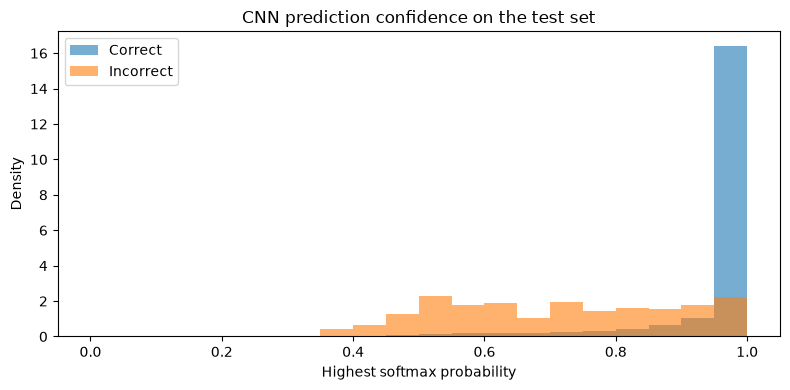

In [35]:
# Confidence (highest softmax probability) of correct and incorrect predictions
confidence_cnn = test_probabilities_cnn.max(axis=1)
correct_mask_cnn = test_predictions_cnn == y_test_cnn

print(f"Mean confidence when correct:   {confidence_cnn[correct_mask_cnn].mean():.3f}")
print(f"Mean confidence when incorrect: {confidence_cnn[~correct_mask_cnn].mean():.3f}")
print(f"Errors made with confidence > 0.9: "
      f"{(confidence_cnn[~correct_mask_cnn] > 0.9).mean():.1%} of all errors")

plt.figure(figsize=(8, 4))
bins = np.linspace(0, 1, 21)
plt.hist(confidence_cnn[correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Correct")
plt.hist(confidence_cnn[~correct_mask_cnn], bins=bins, alpha=0.6, density=True, label="Incorrect")
plt.xlabel("Highest softmax probability")
plt.ylabel("Density")
plt.title("CNN prediction confidence on the test set")
plt.legend()
plt.tight_layout()
plt.show()

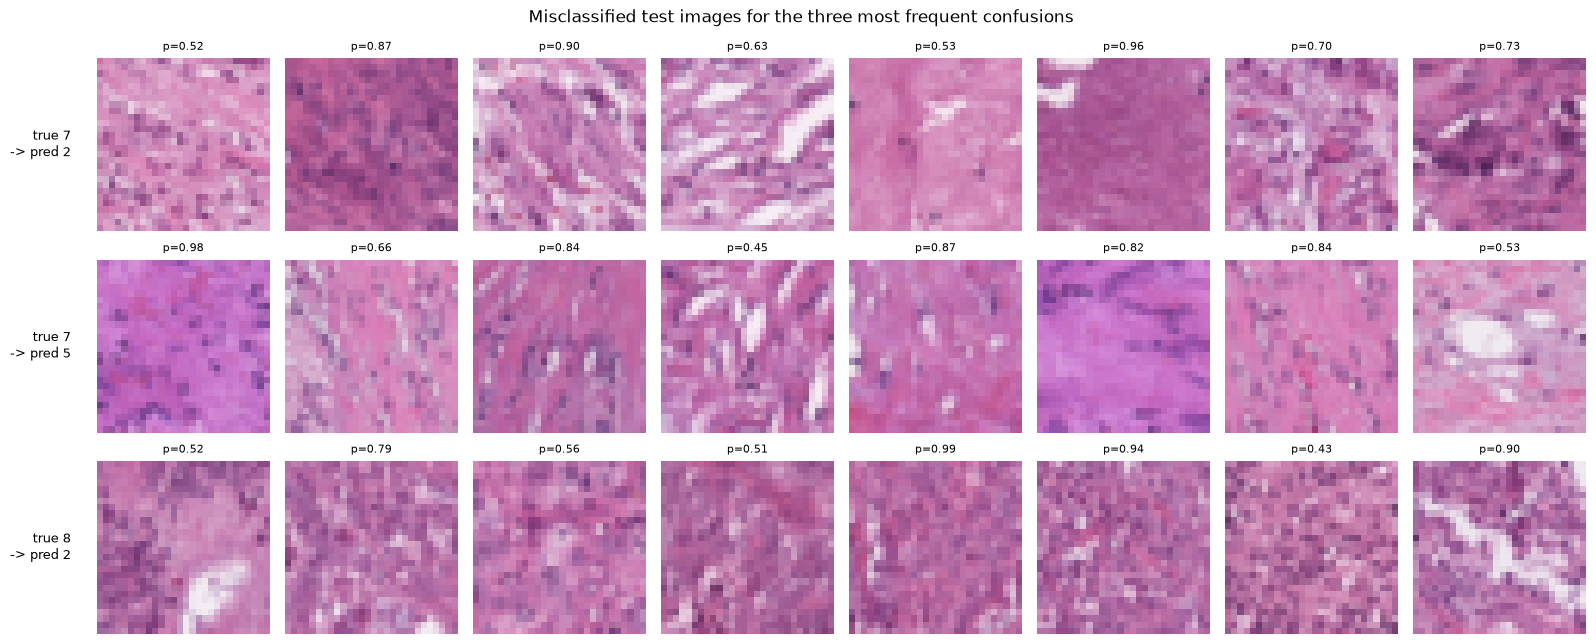

In [36]:
# Misclassified examples from the most frequent confusion pairs
rng_cnn = np.random.default_rng(SEED_CNN)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.6))

for row, (_, pair) in enumerate(top_confusions_cnn.head(3).iterrows()):
    true_id = int(pair["true"].split()[0])
    pred_id = int(pair["predicted"].split()[0])
    pair_rows = np.flatnonzero((y_test_cnn == true_id) & (test_predictions_cnn == pred_id))
    chosen = rng_cnn.choice(pair_rows, size=min(8, len(pair_rows)), replace=False)

    for col in range(8):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(chosen):
            ax.imshow(X_test_img_cnn[chosen[col]])
            ax.set_title(f"p={confidence_cnn[chosen[col]]:.2f}", fontsize=8)
    axes[row, 0].text(
        -0.15, 0.5,
        f"true {true_id}\n-> pred {pred_id}",
        transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=9,
    )

fig.suptitle("Misclassified test images for the three most frequent confusions")
plt.tight_layout()
plt.show()

The final CNN achieved test accuracy of 0.9319, macro F1 of
0.9303, and weighted F1 of 0.9316. It misclassified 545 of
the 8,000 test images. Preprocessing, model construction,
and fitting took 127.74 seconds; test preprocessing and
prediction took 0.41 seconds on the local machine.

Class 7 (cancer-associated stroma) had the lowest F1 score
(0.8223), followed by class 2 (debris, 0.8586).
The largest confusion was class 7 being predicted as class 2
(126 images), followed by class 7 being predicted as class 5
(61 images). The eight most frequent confusion pairs accounted
for 63.7% of all errors.

Mean maximum softmax probability was 0.958 for correct
predictions and 0.712 for incorrect predictions. However,
20.0% of errors had a maximum softmax probability above 0.9.
These scores describe model confidence and should not be
interpreted as calibrated probabilities of correctness.

The results suggest that learned spatial features can improve
classification relative to the shared fixed-feature approach.
However, the models differ in preprocessing, search budgets,
and training procedures, so the comparison does not isolate
the effect of architecture alone.

## 5. AI Acknowledgement

ChatGPT, OpenAI Codex, and Claude Code were used to support
this assignment.

For the Random Forest component, OpenAI Codex assisted with
code development, experiment execution, and summaries of
experiment records. For the MLP component and notebook
integration, ChatGPT assisted with Python environment
troubleshooting, code review and refinement, interpretation
of experimental outputs, and merging the members' contributions.
For the CNN component, Claude Code assisted with code development,
execution, debugging, and drafting explanatory text.

The experiments were executed locally, and the numerical
results reported in this notebook were obtained from those
runs.